# Lecture 13 – Prediction: supervised learning

QSS 20 · Modern Statistical Computing · Fall 2026

Content credit: see the course
[Acknowledgements](https://kengchichang.github.io/QSS20/acknowledgements).

### Agenda

1. **Taxonomy of machine learning.** 
2. **Linear regression.** 
3. **Generalization.** Training against test error, bias and variance,
   overfitting, the train-test split, cross-validation.
4. **Logistic regression**, and the confusion matrix.
5. **k-nearest neighbors.**
6. **Evaluation.** Recall, precision.
7. **Decision trees.**
8. **The disputed Federalist papers**, with five representations.

### Setup: install once

This lecture uses `scikit-learn`, installed in lecture 12. If the import in
the next cells fails, install it in a terminal, not in this notebook:

```bash
conda activate qss20
conda install scikit-learn
```

- Lecture 14 uses it too.
- If an import still fails, restart the kernel (Kernel → Restart Kernel)
  and run the cells again.

### Setup: one thread for scikit-learn

Restart the kernel, then run this cell first, before any other import.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'

- On computers with many cores, scikit-learn and NumPy can start so many
  threads that the kernel crashes. One thread is enough for these data.
- The setting works only if NumPy has not been imported yet in this kernel.

### Setup: imports and folders

Load every package the lecture uses, and name the data folder.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Circle, Ellipse, Rectangle
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    classification_report, confusion_matrix, mean_squared_error)
from sklearn.model_selection import (
    GridSearchCV, cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option('display.max_rows', 20)
pd.set_option('display.max_colwidth', 80)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'
# Show only the last line of an error message.
%xmode Minimal

RAW = Path('../../data/raw')

Exception reporting mode: Minimal


- A few figure cells below have their code collapsed: they draw sketches
  to illustrate an idea, not data. Click the collapsed bar to read them.
- Every model in `sklearn` is a class: `LinearRegression`,
  `LogisticRegression`, `KNeighborsClassifier`, `DecisionTreeClassifier`.
  The rest of the imports split the data, score a model, or draw a tree.

## Part 1: Taxonomy of machine learning

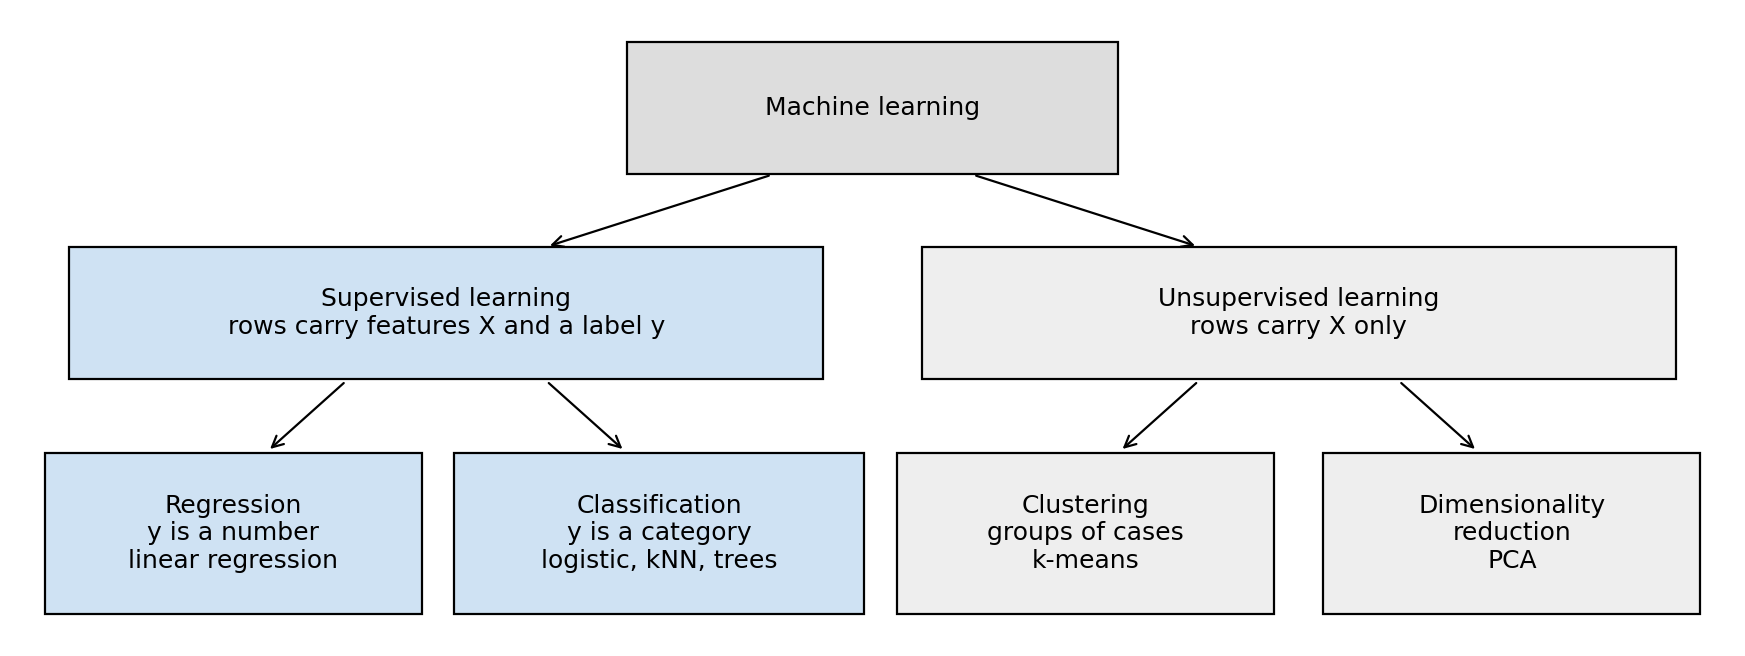

In [3]:
def box(ax, x, y, text, w=2.6, h=0.9, color='#dddddd'):
    ax.add_patch(Rectangle((x - w / 2, y - h / 2), w, h, fc=color,
                           ec='black', lw=0.8))
    ax.text(x, y, text, ha='center', va='center', fontsize=9)

def arrow(ax, x0, y0, x1, y1):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0),
                arrowprops={'arrowstyle': '->', 'lw': 0.8})

fig, ax = plt.subplots(figsize=(11, 4))
ax.set(xlim=(0, 10.4), ylim=(0, 4.2))
ax.axis('off')
box(ax, 5.2, 3.6, 'Machine learning', w=3)
box(ax, 2.6, 2.2,
    'Supervised learning\nrows carry features X and a label y',
    w=4.6, color='#cfe2f3')
box(ax, 7.8, 2.2,
    'Unsupervised learning\nrows carry X only',
    w=4.6, color='#eeeeee')
box(ax, 1.3, 0.7, 'Regression\ny is a number\nlinear regression',
    w=2.3, h=1.1, color='#cfe2f3')
box(ax, 3.9, 0.7,
    'Classification\ny is a category\nlogistic, kNN, trees',
    w=2.5, h=1.1, color='#cfe2f3')
box(ax, 6.5, 0.7, 'Clustering\ngroups of cases\nk-means',
    w=2.3, h=1.1, color='#eeeeee')
box(ax, 9.1, 0.7, 'Dimensionality\nreduction\nPCA',
    w=2.3, h=1.1, color='#eeeeee')
arrow(ax, 4.6, 3.15, 3.2, 2.65)
arrow(ax, 5.8, 3.15, 7.2, 2.65)
arrow(ax, 2.0, 1.75, 1.5, 1.25)
arrow(ax, 3.2, 1.75, 3.7, 1.25)
arrow(ax, 7.2, 1.75, 6.7, 1.25)
arrow(ax, 8.4, 1.75, 8.9, 1.25)
plt.show()

- **Supervised**: the data carry a label `y` that the model must learn
  from the feature columns `X`. Today.
- **Unsupervised**: no label; the model looks for structure among the
  observations. Lecture 14.
- Within supervised learning, the type of `y` decides the task: a number
  is **regression**, a category is **classification**.

### Terminology

| Computer science | Social science | In this lecture |
|---|---|---|
| **label**, target | dependent variable, outcome | a vote margin; a member's party; a paper's author |
| **features** | independent variables, covariates, predictors | a competence score; a DW-NOMINATE score; the TF-IDF weight of each word |
| **training examples** | observations, cases | one race; one paper |

- One row is one case. `X` holds the feature columns, `y` the label
  column.
- The same words mean the same things; the fields name them differently.

### Prediction and training

- A **model** is a function that takes the features of an observation
  and returns a label: a number of points, or a category.
- **Training** (fitting) chooses the model from data whose labels we
  know, by making some measure of error as small as possible on those
  data.
- **Prediction** applies the model to an observation whose label we do
  not know: a disputed paper, or a race we hide from the fit on purpose.
- Part 2 fits the simplest model, a line. Part 3 asks how we know that a
  model works on data it has not seen.

## Part 2: linear regression

### Which person is the more competent?

<img src="images/face_pair_2004.png" width="620" alt="Two black-and-white head shots of men in suits, side by side, above the caption: Which person is the more competent?">

Decide in one second, before the next line.

- The 2004 Wisconsin Senate race. Left: Russ Feingold (D), 55 percent.
  Right: Tim Michels (R), 44 percent.
- This pair is Figure 1 of the paper the data come from. Students who
  did not know either man picked the winner.

### Does a face win elections?

- [Todorov, Mandisodza, Goren, and Hall (2005)](https://doi.org/10.1126/science.1110589),
  *Science*, showed Princeton students black-and-white
  head shots of the two candidates in a US Senate race for under a second
  and asked which one looked more **competent**. The students did not know
  the candidates, their party, or who held the seat.
- `d.comp` is the share of subjects who chose the Democrat. If a snap
  judgment of a face carries nothing, it should not line up with the vote.
- One row is one race: 119 Senate races, 2000 to 2006. The outcome is the
  Democrat's margin in the two-party vote. The chapter's example is
  Wisconsin 2004: Feingold (D) beat Michels (R) with a competence share of
  0.549 and a margin of 11 points.

### The data

| Variable | Description |
|---|---|
| `year`, `state` | the election |
| `winner`, `loser` | names |
| `w.party`, `l.party` | party of the winner, of the loser |
| `d.votes`, `r.votes` | votes for the Democrat, for the Republican |
| `d.comp`, `r.comp` | competence share for the Democrat, for the Republican |

In [4]:
face = pd.read_csv(RAW / 'face.csv')
face['d_share'] = face['d.votes'] / (face['d.votes'] + face['r.votes'])
face['r_share'] = face['r.votes'] / (face['d.votes'] + face['r.votes'])
face['diff_share'] = face['d_share'] - face['r_share']
face[['year', 'state', 'winner', 'loser', 'w.party', 'd.comp',
      'diff_share']].head()

,year,state,winner,loser,w.party,d.comp,diff_share
0,2000,CA,Feinstein,Campbell,D,0.564568,0.210129
1,2000,DE,Carper,Roth,D,0.341912,0.119431
2,2000,FL,Nelson,McCollum,D,0.612368,0.049907
3,2000,GA,Miller,Mattingly,D,0.541533,0.196517
4,2000,HI,Akaka,Carroll,D,0.680232,0.495770


- `d_share` is the Democrat's share of the votes cast for the two major
  candidates; `diff_share` is the margin, positive when the Democrat won.
- `d.comp` and `r.comp` sum to 1, so one of them carries all the
  information. We use `d.comp`.

### Margin against competence

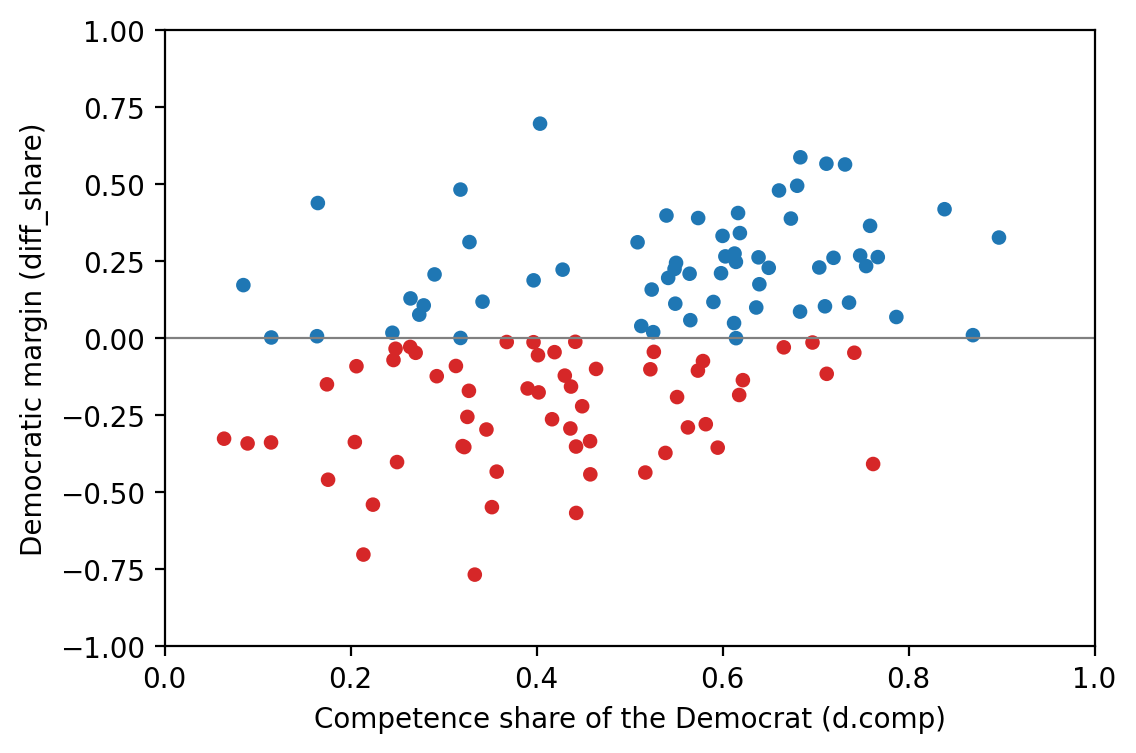

In [5]:
colors = face['w.party'].map({'D': 'C0', 'R': 'C3'})
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(face['d.comp'], face['diff_share'], c=colors, s=18)
ax.axhline(0, color='grey', lw=0.8)
ax.set(xlabel='Competence share of the Democrat (d.comp)',
       ylabel='Democratic margin (diff_share)',
       xlim=(0, 1), ylim=(-1, 1))
plt.show()

In [6]:
face['d.comp'].corr(face['diff_share']).round(3)

0.433

- Blue points are races the Democrat won, red the Republican. The cloud
  slopes upward: the more competent the Democrat's face looked, the larger
  the Democratic margin, on average.
- The correlation is 0.43: a moderate linear relation, far from a line.

### The linear regression model

$$Y = \alpha + \beta X + \epsilon$$

| Symbol | Name | Where it lives |
|---|---|---|
| $x_i$ | predictor of row $i$ | the column `d.comp` |
| $y_i$ | outcome of row $i$ | the column `diff_share`, computed from two stored columns |
| $\alpha$, $\beta$ | intercept, slope | unknown; the fit estimates them as $\hat\alpha$, $\hat\beta$ |
| $\epsilon_i$ | error | unobserved: what the line cannot explain |
| $\hat y_i = \hat\alpha + \hat\beta x_i$ | fitted value | computed from the estimates, one per row |
| $\hat\epsilon_i = y_i - \hat y_i$ | residual | computed, one per row |

- $\alpha$ is the average outcome when $x = 0$. $\beta$ is the average
  change in the outcome for one unit more of $x$.
- The stored columns are $x_i$ and $y_i$. Everything else is calculated
  from them.

### Least squares

Any line gives a residual for every row. **Least squares** chooses the line
whose residuals, squared and summed, are smallest:

$$\text{SSR} = \sum_{i=1}^{n} \hat\epsilon_i^2
= \sum_{i=1}^{n} (y_i - \hat\alpha - \hat\beta x_i)^2,
\qquad
\text{RMSE} = \sqrt{\text{SSR} / n}$$

The answer has a closed form (QSS equations 4.6 and 4.7):

$$\hat\beta = \frac{\sum_i (y_i - \bar y)(x_i - \bar x)}
{\sum_i (x_i - \bar x)^2},
\qquad
\hat\alpha = \bar y - \hat\beta \bar x$$

In [7]:
x = face['d.comp']
y = face['diff_share']
numerator = ((y - y.mean()) * (x - x.mean())).sum()
denominator = ((x - x.mean()) ** 2).sum()
beta = numerator / denominator
alpha = y.mean() - beta * x.mean()
round(alpha, 4), round(beta, 4)

(-0.3122, 0.6604)

- Intercept −0.312, slope 0.660. A Democrat whom no subject judged more
  competent is expected to lose by 31 points; each 0.1 of competence share
  adds 6.6 points of margin.
- The slope is the correlation times the ratio of standard deviations:
  0.433 × 0.294 / 0.193 = 0.660.

### `LinearRegression` does the same calculation

Every `sklearn` model works the same way: create it, `fit` it on the
features `X` and the label `y`, then read its attributes or ask it for
outputs.

In [8]:
X = face[['d.comp']]
y = face['diff_share']
model = LinearRegression()
model.fit(X, y)
model.intercept_.round(4), model.coef_.round(4)

(-0.3122, array([0.6604]))

- `X` is a DataFrame with one column, so the model knows the feature's
  name; `y` is a Series. `fit` takes the two as positional arguments.
- The attributes end in an underscore: `intercept_`, `coef_`. The
  underscore marks a value learned from the data. `coef_` is an array with
  one entry per feature column.
- The numbers match the formula.

### The fitted line, annotated

The pieces of the model on the plot: every residual as a thin segment,
one race's outcome, fitted value, and residual in full, the intercept,
and the means of $x$ and $y$.

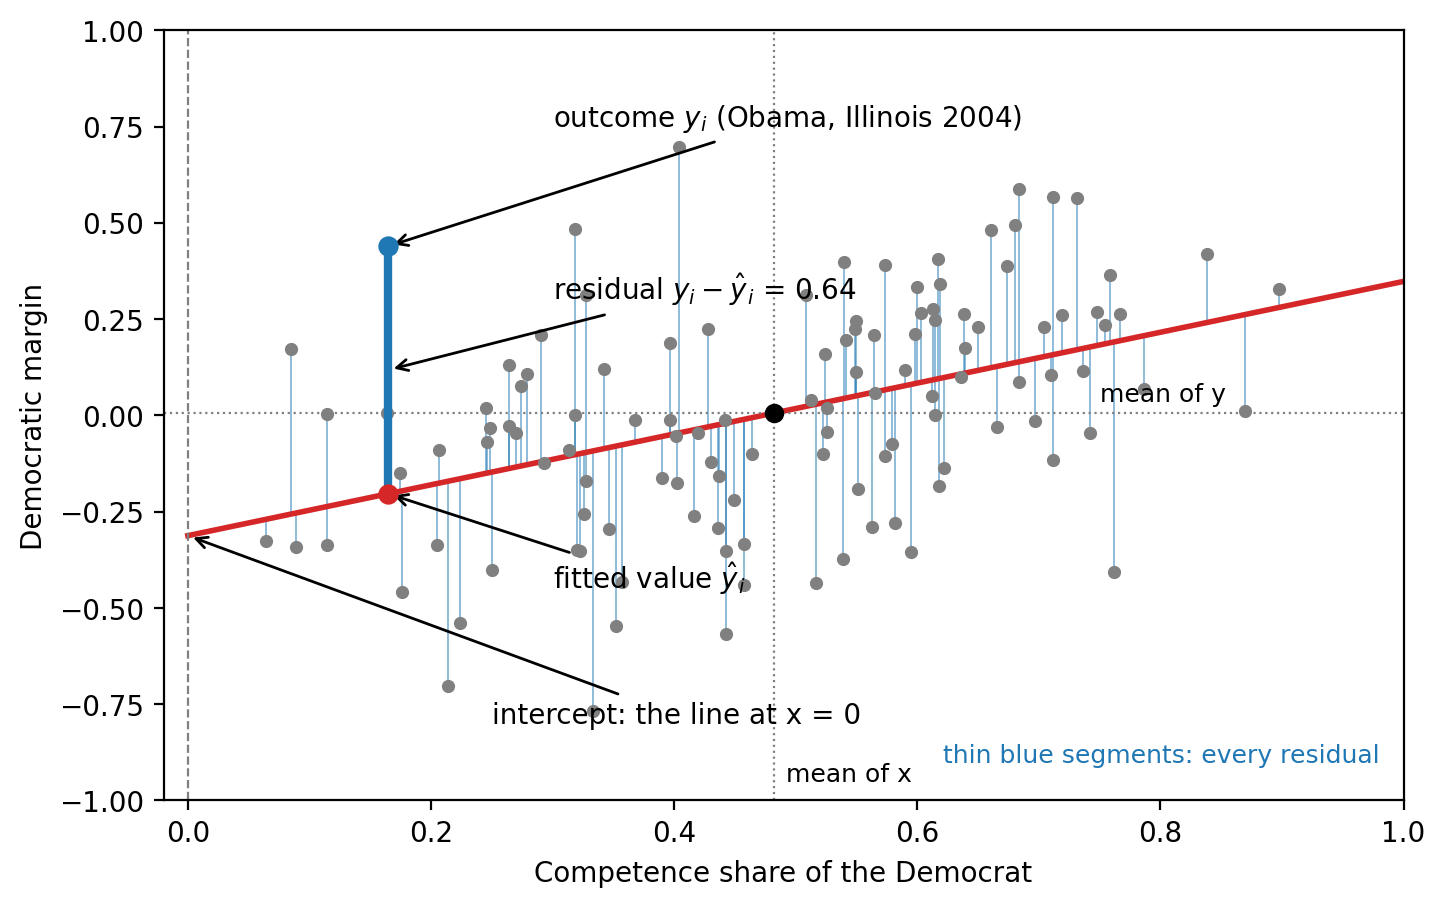

In [9]:
fitted = model.predict(X)
row = face.index[face['winner'] == 'Obama'][0]
x0, y0 = face.loc[row, 'd.comp'], face.loc[row, 'diff_share']
y0_hat = fitted[row]
line_x = np.array([0, 1])
line_y = model.predict(pd.DataFrame({'d.comp': line_x}))

fig, ax = plt.subplots(figsize=(8, 5))
ax.vlines(x, fitted, y, color='C0', lw=0.7, alpha=0.5)
ax.scatter(x, y, s=14, color='grey', zorder=3)
ax.plot(line_x, line_y, color='C3', lw=2, zorder=2)
ax.axvline(0, ls='--', color='grey', lw=0.8)
ax.axvline(x.mean(), ls=':', color='grey', lw=0.8)
ax.axhline(y.mean(), ls=':', color='grey', lw=0.8)
ax.scatter([x.mean()], [y.mean()], color='black', zorder=4)
ax.plot([x0, x0], [y0, y0_hat], color='C0', lw=3, zorder=4)
ax.scatter([x0], [y0], color='C0', s=40, zorder=5)
ax.scatter([x0], [y0_hat], color='C3', s=40, zorder=5)
arrow = {'arrowstyle': '->'}
ax.annotate('intercept: the line at x = 0', xy=(0, model.intercept_),
            xytext=(0.25, -0.8), arrowprops=arrow)
ax.annotate('outcome $y_i$ (Obama, Illinois 2004)', xy=(x0, y0),
            xytext=(0.3, 0.75), arrowprops=arrow)
ax.annotate(r'fitted value $\hat y_i$', xy=(x0, y0_hat),
            xytext=(0.3, -0.45), arrowprops=arrow)
ax.annotate(r'residual $y_i - \hat y_i$ = 0.64',
            xy=(x0, (y0 + y0_hat) / 2), xytext=(0.3, 0.3),
            arrowprops=arrow)
ax.text(x.mean() + 0.01, -0.95, 'mean of x', fontsize=9)
ax.text(0.75, y.mean() + 0.03, 'mean of y', fontsize=9)
ax.text(0.98, -0.9, 'thin blue segments: every residual', fontsize=9,
        color='C0', ha='right')
ax.set(xlabel='Competence share of the Democrat',
       ylabel='Democratic margin', xlim=(-0.02, 1), ylim=(-1, 1))
plt.show()

- The blue point is Illinois 2004: Obama beat Keyes by 44 points with a
  competence share of 0.165. The line expects a loss by 20 points, the
  red point. The thick segment between them is the residual, 0.64, the
  second-largest in the data after Kennedy, Massachusetts 2000 (0.74).
- Every race has a residual, the thin segment from its point to the
  line. Least squares makes the sum of their squares as small as any
  line can.
- The line passes through the point of means, and the residuals average
  exactly zero. Both follow from the formulas for $\hat\alpha$ and
  $\hat\beta$.

### `predict` and the error of the line

`predict(X)` applies the fitted line to each row of `X` and returns the
fitted values.

In [10]:
fitted = model.predict(X)
residual = y - fitted
rmse = np.sqrt(mean_squared_error(y, fitted))
round(residual.mean(), 10), round(rmse, 3)

(-0.0, 0.264)

In [11]:
new = pd.DataFrame({'d.comp': [0.3, 0.5, 0.7]})
model.predict(new).round(3)

array([-0.114,  0.018,  0.15 ])

- RMSE 0.264: the line is off by 26 points of margin on average. The
  constant model, the mean margin for every race, is off by 29.
- Competence lines up with the outcome, but loosely. Faces carry some
  signal; elections turn on much else.
- `predict` takes a DataFrame with the same column name as `X`.

### `LinearRegression`: what to write

| Goal | Write | Returns |
|---|---|---|
| Create the model | `model = LinearRegression()` | an unfitted model |
| Fit it | `model.fit(X, y)` | the same model, with coefficients |
| The coefficients | `model.intercept_`, `model.coef_` | $\hat\alpha$; an array of $\hat\beta$, one per column |
| Fitted values for rows | `model.predict(X_new)` | an array, one number per row |
| Error of the fit | `mean_squared_error(y, model.predict(X))` | MSE; take `np.sqrt` for RMSE |
| Share of variance explained | `model.score(X, y)` | $R^2$ |

With two or more feature columns in `X`, nothing changes except the length
of `coef_`: the line becomes a plane.

## Part 3: generalization

### Two ways to study for an exam

- You and Billy are studying for an exam. To test yourselves, you each
  take a practice exam once and read the solutions afterwards. The logic:
  do well on the practice exam, and you should do well on the real one.
- **Your strategy:** memorize the answers to every practice question:
  "Question 1: A; Question 2: C; Question 3: A."
- **Billy's strategy:** learn the ideas behind the solutions: "the TF-IDF
  weight of a word in a paper is large when the word is frequent in that
  paper and rare across the collection."

### ❓ Question

Who does better on the practice exam? Who will probably do better on the
real exam?

<details><summary>Answer</summary>

**You win the practice exam; Billy wins the real one.** Your strategy repeats
the answers it was shown and has nothing to say about a question it has
not seen. The practice exam is the training data; the real exam is the
data the model has not seen. A perfect score on the training data is no
evidence about new data when the strategy was to memorize.

</details>

### A model with $R^2 = 1$

A post on X during the 2024 campaign:

<img src="images/tweet_r2_1.png" width="640" alt="A post by @Luky_BB: That's cute, but my model correctly predicts all general elections since 2000, has an R2 of 1, and predict Kamala will win with over 800 electoral votes. Below it, a chart titled Predicted Democratic Electoral College Votes: six points from 2000 to 2020 between 227 and 365, a dotted curve through all six, R squared = 1, rising past 800 at 2024.">

- Six elections, and a curve through all six: $R^2 = 1$, training error
  zero.
- For 2024 the curve says more than 800 electoral votes. There are 538.
  Harris received 226.
- A perfect fit to the data we have is no evidence about the next
  observation. The rest of this part says how to tell a model that
  learned from a model that memorized.

### Training error

- The RMSE of 0.264 in Part 2 was computed on the 119 races the line was
  fitted on. That number is the **training error**.
- So far, model A was better than model B when its training error was
  lower. The tweet shows the problem: a flexible enough model drives the
  training error to zero and learns nothing.
- The 119 races are a sample. The question is whether the model works on
  other races from the same population, which the fit never sees.

### Two samples from one population

A simulation. In the population, $y = x^3$ plus noise; we draw
two samples of 100 observations from it. In practice we see one sample
and never the population curve. If we could see the curve, there would
be no model to build.

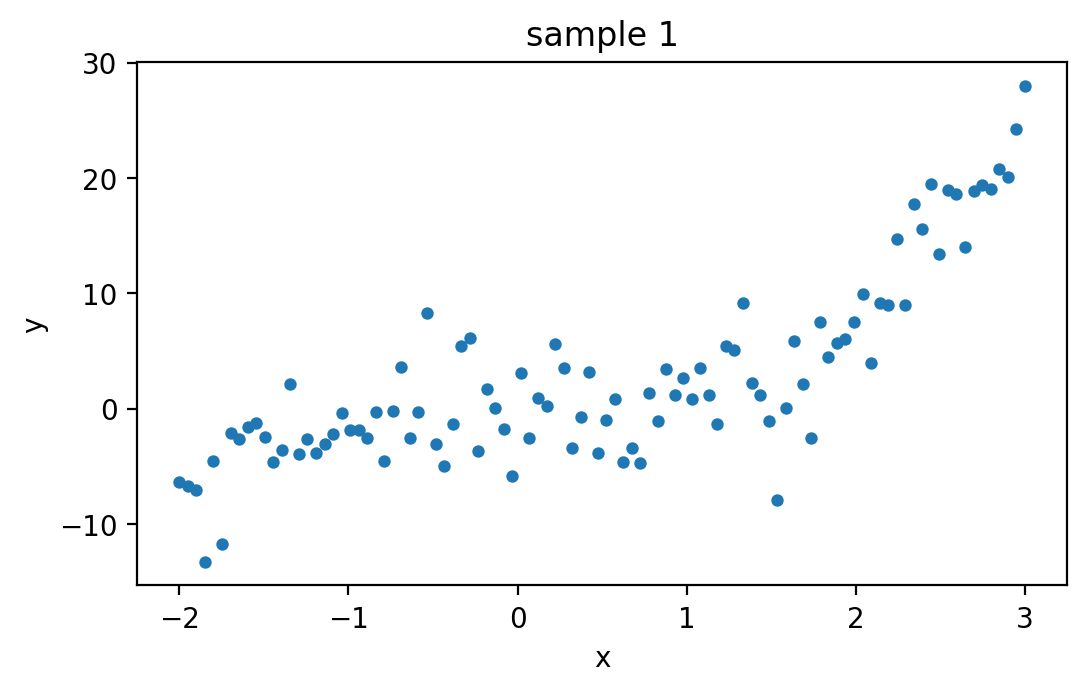

In [12]:
rng = np.random.default_rng(23)

def sample_from_pop(n=100):
    xs = np.linspace(-2, 3, n)
    return pd.DataFrame({'x': xs, 'y': xs ** 3 + rng.normal(0, 3, n)})

sample_1 = sample_from_pop()
sample_2 = sample_from_pop()

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.scatter(sample_1['x'], sample_1['y'], s=12)
ax.set(title='sample 1', xlabel='x', ylabel='y')
plt.show()

- One observation is one pair $(x_i, y_i)$. The relation looks roughly
  cubic; the noise hides the exact curve.
- Both samples come from the same population, so a model fitted on
  sample 1 should work on sample 2 if it learned the population and not
  the noise.

### Three models fitted on sample 1

A line, a cubic, and a polynomial of degree 25. `Polynomial.fit` chooses
the coefficients by least squares, as `LinearRegression` did in Part 2.

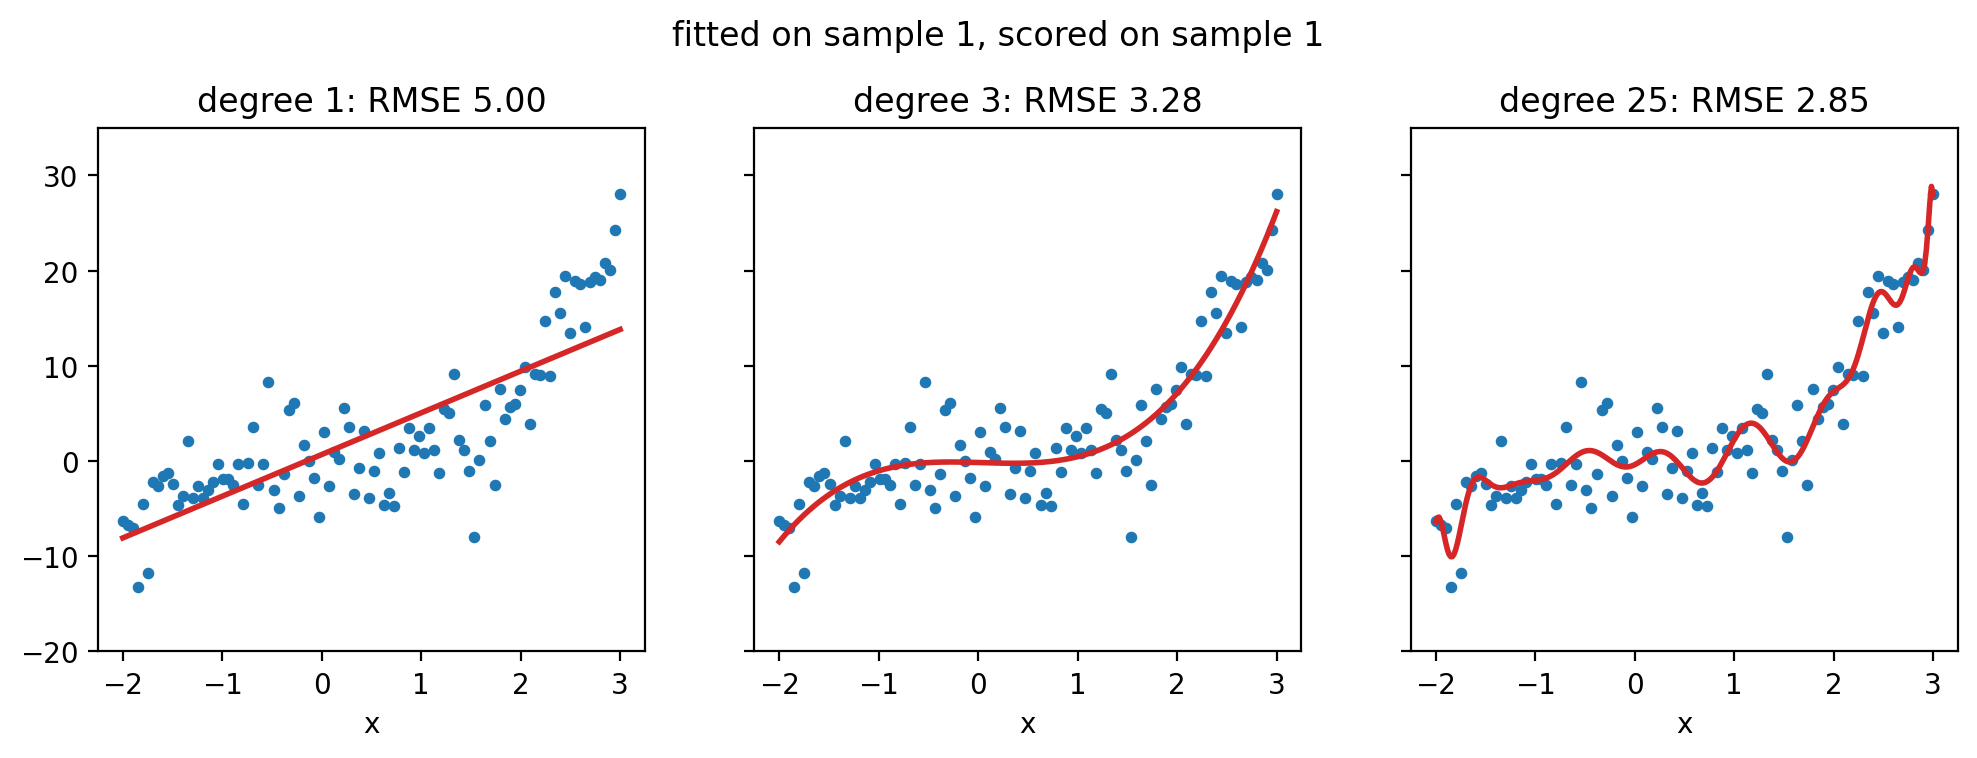

In [13]:
def poly_fit(sample, degree):
    return np.polynomial.Polynomial.fit(sample['x'], sample['y'],
                                        degree)

def poly_rmse(sample, model):
    return np.sqrt(np.mean((sample['y'] - model(sample['x'])) ** 2))

def show_fits(sample, models, title):
    xs = np.linspace(-2, 3, 300)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
    for ax, (degree, model) in zip(axes, models.items()):
        score = poly_rmse(sample, model)
        ax.scatter(sample['x'], sample['y'], s=10)
        ax.plot(xs, model(xs), color='C3', lw=2)
        ax.set(title=f'degree {degree}: RMSE {score:.2f}',
               ylim=(-20, 35), xlabel='x')
    fig.suptitle(title, y=1.04)
    plt.show()

models_1 = {d: poly_fit(sample_1, d) for d in [1, 3, 25]}
show_fits(sample_1, models_1, 'fitted on sample 1, scored on sample 1')

- The degree-25 curve has the lowest training error, 2.85. It bends
  toward single points. The line misses the bend at both ends, 5.00.
- By training error, degree 25 wins. Now score the same three models on
  sample 2, which they never saw.

### The same three models, scored on sample 2

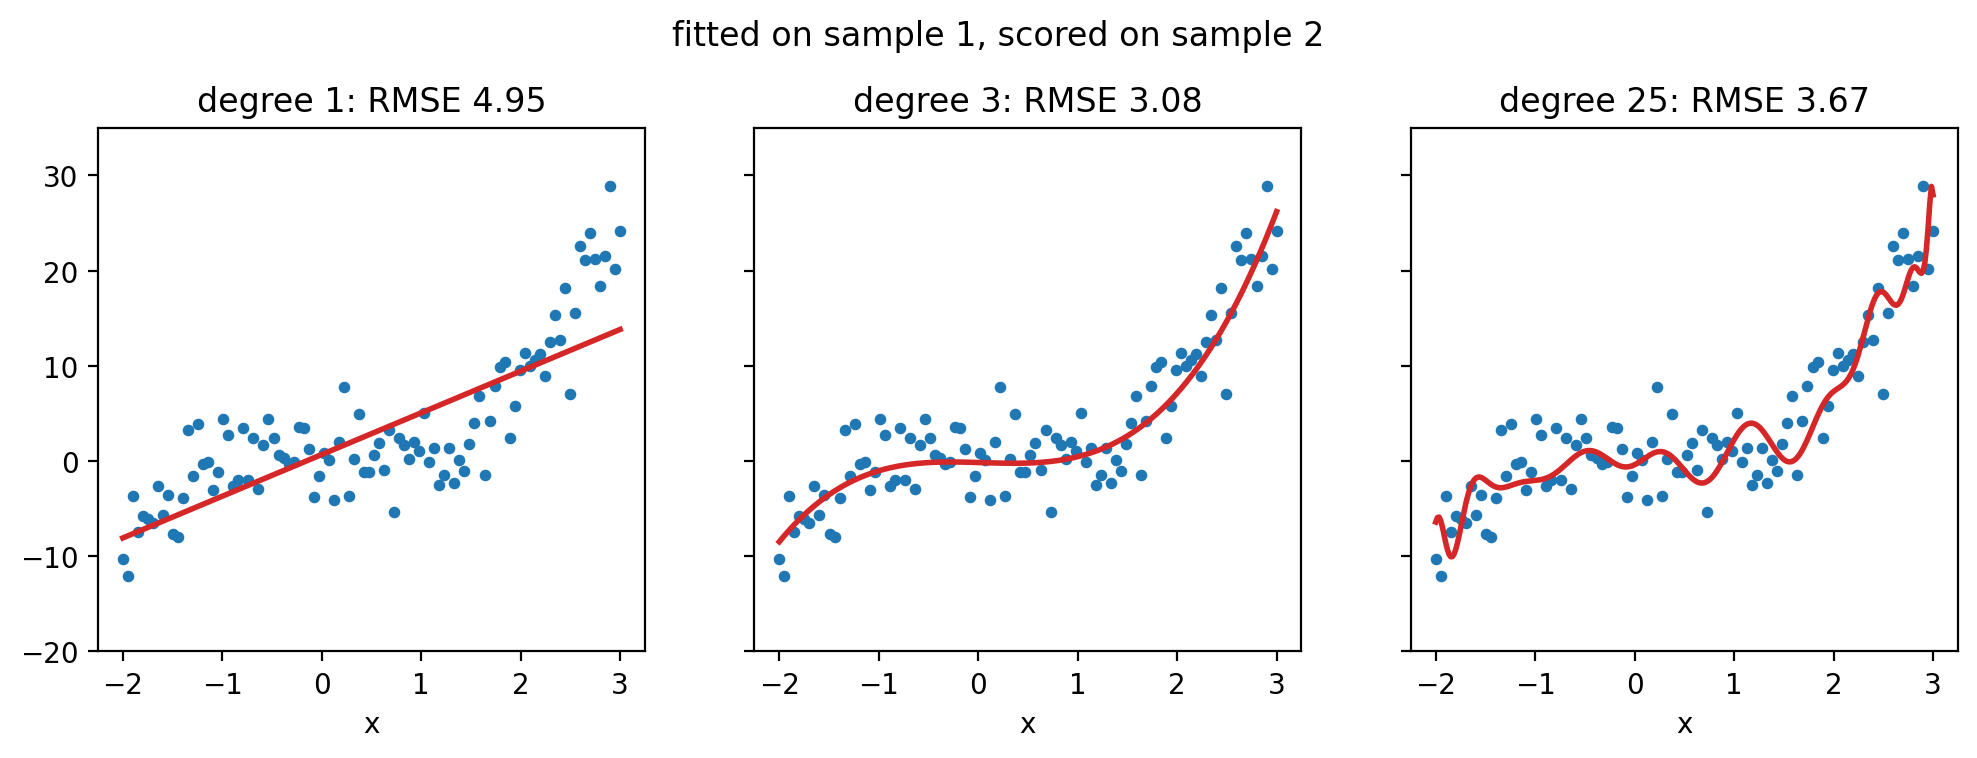

In [14]:
show_fits(sample_2, models_1, 'fitted on sample 1, scored on sample 2')

- Now the cubic has the lowest error, 3.08, and degree 25 rises to 3.67:
  the wiggles that fitted the noise of sample 1 miss the noise of
  sample 2.
- The cubic **generalizes** to data it did not see; degree 25
  **memorized** the data it saw.

### Fit each model on both samples

What happens to each model when the sample changes? Fit degrees 1, 3, and
25 on sample 2 as well and draw the two fits together with the population
curve $y = x^3$.

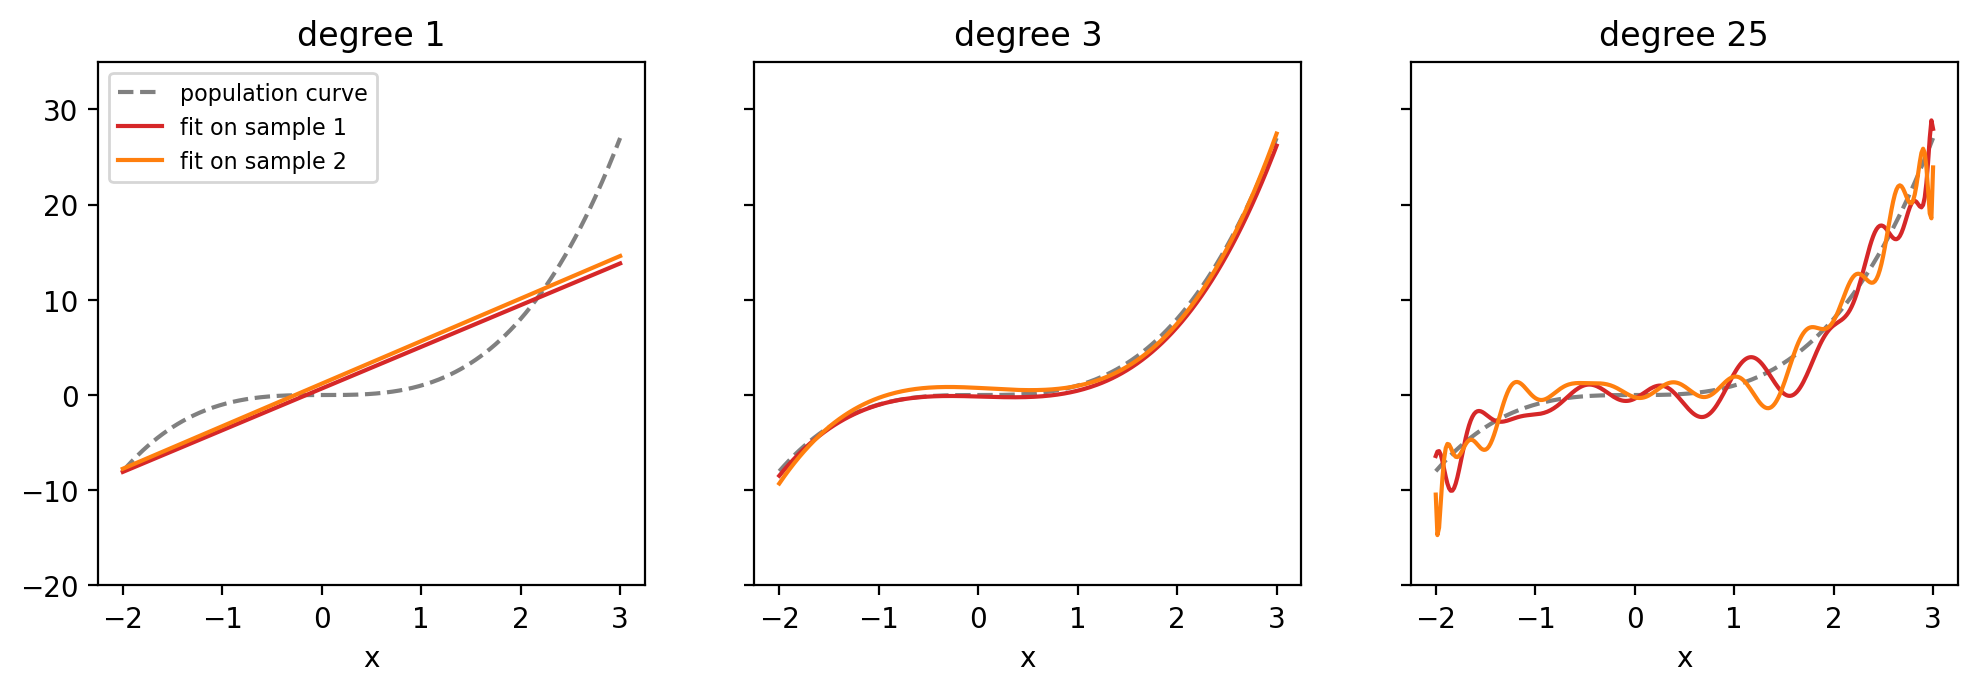

In [15]:
models_2 = {d: poly_fit(sample_2, d) for d in [1, 3, 25]}
xs = np.linspace(-2, 3, 300)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, degree in zip(axes, [1, 3, 25]):
    ax.plot(xs, xs ** 3, color='grey', ls='--',
            label='population curve')
    ax.plot(xs, models_1[degree](xs), color='C3',
            label='fit on sample 1')
    ax.plot(xs, models_2[degree](xs), color='C1',
            label='fit on sample 2')
    ax.set(title=f'degree {degree}', ylim=(-20, 35), xlabel='x')
axes[0].legend(fontsize=8)
plt.show()

- Degree 25: the two fits disagree with each other along the whole
  range, and each wiggles around the dashed curve. The model changes
  with the sample.
- Degree 1: the two fits agree with each other and both miss the bend in
  the same way. The model is stable and wrong.
- Degree 3: the two fits agree and sit on the dashed curve.

### Bias and variance

Fit a model of a given form (say, a cubic) on many samples from one
population. Its error on new data has three sources.

| Source | Definition | Sign of |
|---|---|---|
| **Model variance** | how much the fitted model's output at a given $x$ changes from sample to sample | **overfitting**: the rule is flexible enough to fit the noise of its sample |
| **Model bias** | how far the fitted model's output at $x$ is from the truth, averaged over samples | **underfitting**: the rule is too simple for the relation |
| **Observation error** | the noise in $y$ itself | nothing to fit; only better data reduce it |

- Degree 25 has high variance; degree 1 has high bias; the cubic has
  little of either. Low variance is good, and low bias is good.

### Darts

The bullseye is the truth for one observation. Each dart is the output
of a model fitted on one sample.

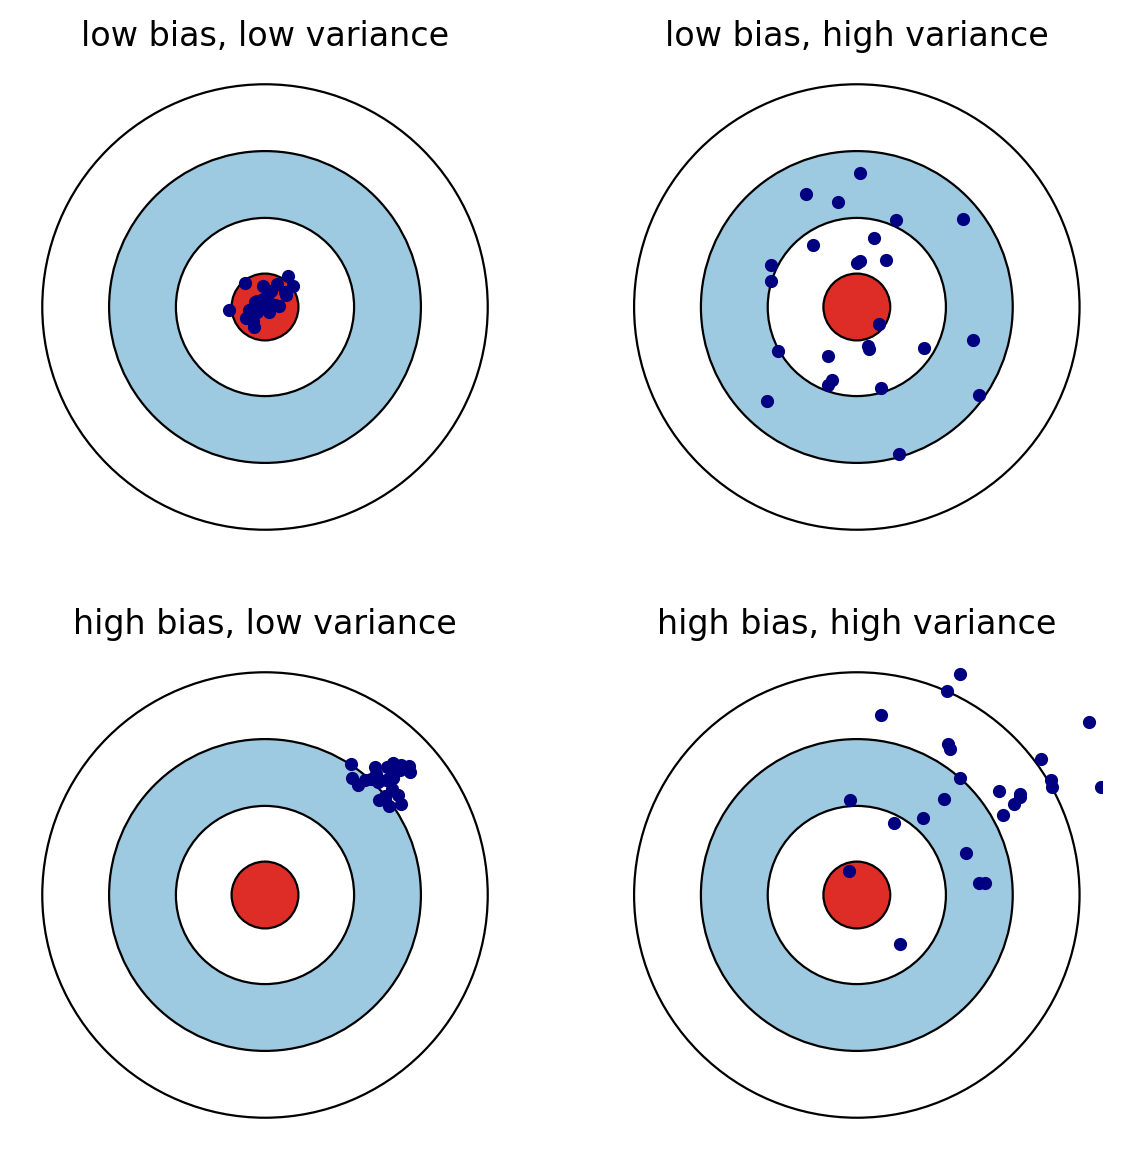

In [16]:
rng = np.random.default_rng(0)
boards = {'low bias, low variance': ((0, 0), 0.07),
          'low bias, high variance': ((0, 0), 0.3),
          'high bias, low variance': ((0.55, 0.5), 0.07),
          'high bias, high variance': ((0.55, 0.5), 0.3)}
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for ax, (name, (center, spread)) in zip(axes.flat, boards.items()):
    for radius, color in [(1, 'white'), (0.7, '#9ecae1'),
                          (0.4, 'white'), (0.15, '#de2d26')]:
        ax.add_patch(Circle((0, 0), radius, fc=color, ec='black',
                            lw=0.8))
    darts = rng.normal(center, spread, size=(25, 2))
    ax.scatter(darts[:, 0], darts[:, 1], s=14, color='navy', zorder=3)
    ax.set(title=name, xlim=(-1.1, 1.1), ylim=(-1.1, 1.1),
           aspect='equal')
    ax.axis('off')
plt.show()

- Top left is the goal: on target, every time. Degree 1 sits bottom
  left, the same wrong answer on every sample. Degree 25 sits top right,
  right on average and scattered.
- Bottom right is a model with the wrong form that still chases the noise:
  the worst of both.

### The trade-off

On new data, the expected squared error of a model decomposes as

$$\text{error} = \text{bias}^2 + \text{variance} + \text{observation error}$$

As a model gets more flexible, its bias falls and its variance rises. The
error on new data is lowest in between.

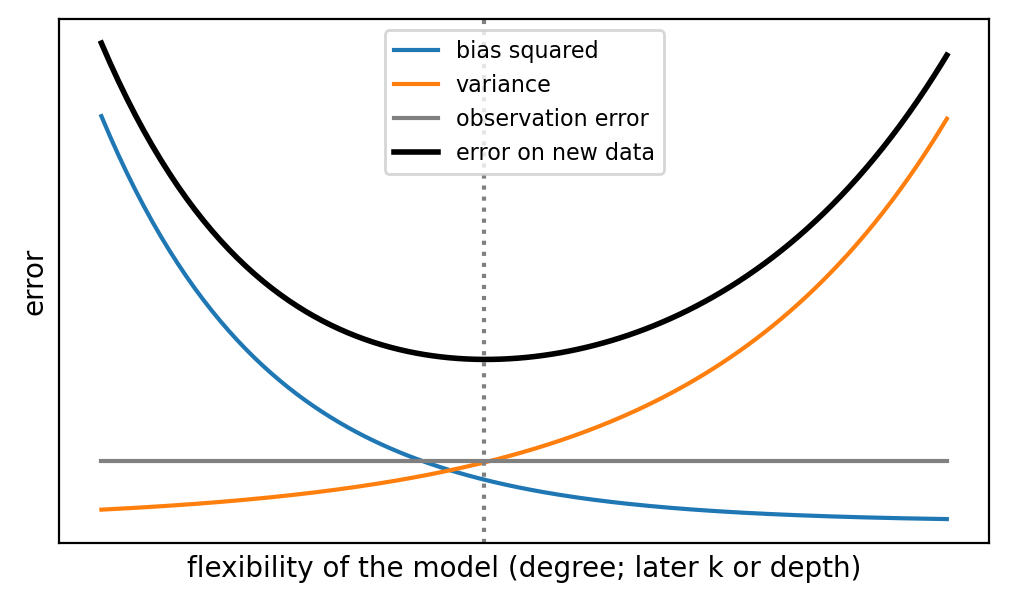

In [17]:
flex = np.linspace(0, 1, 200)
bias_sq = np.exp(-5 * flex)
variance = 0.03 * np.exp(3.5 * flex)
noise = np.full_like(flex, 0.15)
total = bias_sq + variance + noise
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(flex, bias_sq, label='bias squared')
ax.plot(flex, variance, label='variance')
ax.plot(flex, noise, label='observation error', color='grey')
ax.plot(flex, total, label='error on new data', color='black', lw=2)
ax.axvline(flex[total.argmin()], ls=':', color='grey')
ax.set(xlabel='flexibility of the model (degree; later k or depth)',
       ylabel='error', xticks=[], yticks=[])
ax.legend(fontsize=8)
plt.show()

- A sketch, not a computation: the shapes hold for the models of this
  course. The dotted line marks the flexibility with the lowest error on
  new data: the cubic, in the simulation.
- The settings that control flexibility are the ones we choose by hand:
  the degree here, the number of neighbors $k$ and the tree depth later.

### Parameters and hyperparameters

- A **parameter** is a number the fit learns from the data: the
  coefficients of the cubic, the slope and intercept of Part 2.
- A **hyperparameter** is a number we choose before the fit: the degree.
  Whatever the sample looked like, the left-most model had to be a line,
  because we chose its degree in advance. Call them knobs.
- The question of this part, in practical form: **how do we set the
  knob?** Degree 3 beat degree 25 on sample 2. In practice there is no
  sample 2, so we make one.

### Make a second sample: the train-test split

Hold out a share of the data before the fit. The held-out data play the
part of sample 2.

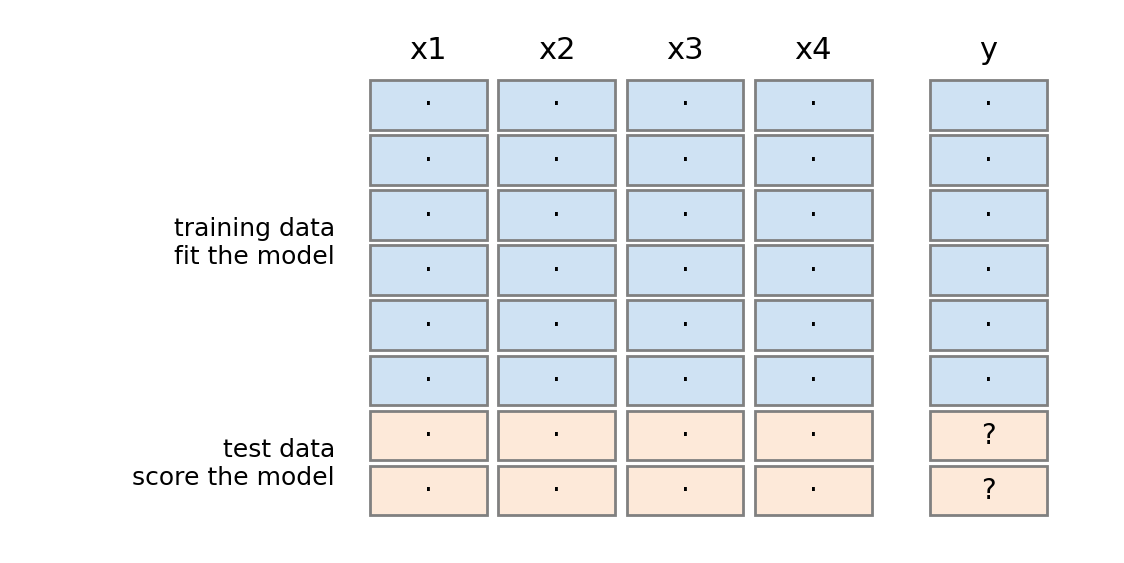

In [18]:
fig, ax = plt.subplots(figsize=(7, 3.4))
cols = ['x1', 'x2', 'x3', 'x4', 'y']
n_rows, n_train = 8, 6
for r in range(n_rows):
    color = '#cfe2f3' if r < n_train else '#fde9d9'
    for c, name in enumerate(cols):
        x_cell = c * 1.1 + (0.4 if name == 'y' else 0)
        rect = Rectangle((x_cell, -r), 1, 0.9, fc=color, ec='grey')
        ax.add_patch(rect)
        shown = '?' if (name == 'y' and r >= n_train) else '·'
        ax.text(x_cell + 0.5, -r + 0.45, shown, ha='center',
                va='center')
for c, name in enumerate(cols):
    x_cell = c * 1.1 + (0.4 if name == 'y' else 0)
    ax.text(x_cell + 0.5, 1.3, name, ha='center', fontsize=11)
ax.text(-0.3, -(n_train - 1) / 2 + 0.45, 'training data\nfit the model',
        ha='right', va='center', fontsize=9)
ax.text(-0.3, -(n_rows - 1 + n_train) / 2 + 0.45,
        'test data\nscore the model', ha='right', va='center',
        fontsize=9)
ax.set(xlim=(-3, 6.3), ylim=(-n_rows + 0.5, 2))
ax.axis('off')
plt.show()

- Blue rows, the training data: the model reads `x1` to `x4` **and**
  `y`, and is fitted. Orange rows, the test data: the model reads `x1`
  to `x4` only, answers `y`, and we compare with the `y` we hid.
- Every score we report comes from the test data.

### `train_test_split`

- `train_test_split(X, y, test_size=0.25, random_state=42)` returns four
  objects, in this order: `X_train, X_test, y_train, y_test`.
- The split is random. `test_size` is the share held out, a quarter in
  this course: more training data give a better model, more test data a
  better estimate of its error. `random_state` fixes the draw so every
  run gives the same split. `stratify=y` keeps each category's share the
  same in both parts when `y` is a category.
- Fit on the training data only. Score on the test data. The test data
  are a new sample from the same population, and that is the only thing
  that catches a model that memorized.

### Training and test error against the degree

Split sample 1, fit every degree from 1 to 25 on the training data, and
score each model on both parts.

In [19]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sample_1[['x']], sample_1['y'], test_size=0.25, random_state=23)


In [20]:
train_part = pd.DataFrame({'x': X_tr['x'], 'y': y_tr})
train_part

,x,y
4,-1.797980,-4.517903
53,0.676768,-3.396405
5,-1.747475,-11.715047
81,2.090909,3.937697
98,2.949495,24.257670
...,...,...
31,-0.434343,-4.945365
54,0.727273,-4.727558
73,1.686869,2.143435
40,0.020202,3.073760


In [21]:
test_part = pd.DataFrame({'x': X_te['x'], 'y': y_te})
test_part

,x,y
26,-0.686869,3.606020
80,2.040404,9.918042
82,2.141414,9.138433
68,1.434343,1.211233
77,1.888889,5.656357
...,...,...
85,2.292929,8.949240
28,-0.585859,-0.337260
8,-1.595960,-1.574878
11,-1.444444,-4.618722


In [22]:
degrees = range(1, 26)
train_err, test_err = [], []
for degree in degrees:
    model = poly_fit(train_part, degree)
    train_err.append(poly_rmse(train_part, model))
    test_err.append(poly_rmse(test_part, model))
errors = pd.DataFrame({'training error': train_err,
                       'test error': test_err}, index=degrees)
errors.round(2).T

,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
training error,5.17,4.13,3.39,3.39,3.38,3.35,3.35,3.33,3.28,3.08,...,2.95,2.93,2.93,2.84,2.76,2.71,2.64,2.63,2.63,2.63
test error,4.48,4.33,3.00,3.01,2.99,3.04,3.04,3.07,3.18,3.15,...,3.49,3.47,3.47,3.40,3.88,4.02,4.25,4.25,4.25,4.24


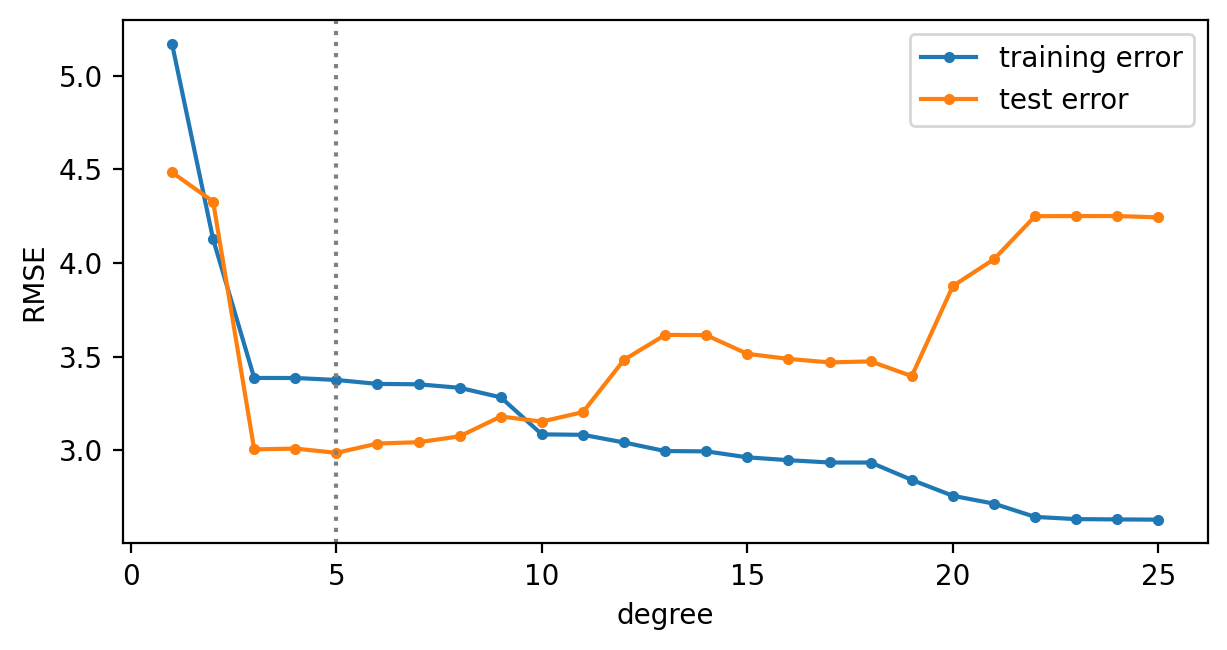

In [23]:
fig, ax = plt.subplots(figsize=(7, 3.4))
errors.plot(ax=ax, marker='o', ms=3)
ax.axvline(errors['test error'].idxmin(), ls=':', color='grey')
ax.set(xlabel='degree', ylabel='RMSE')
plt.show()

- The training error falls with every degree, 5.2 to 2.6: more
  flexibility fits the training data better, every time.
- The test error falls to a valley at degrees 3 to 5, near 3.0, then
  rises to 4.2. We set the knob at the valley.
- The test error can sit below the training error, as it does at degree
  3: these 25 test observations happen to be easier. The shapes are what matter.

### The test data chose the degree

- The valley chose the degree: we fitted 25 models and kept the one with
  the lowest test error. That choice used the test data.
- The test score now does two jobs. It picked the knob, and it reports
  how good the model is. The lowest of 25 scores is low partly by luck:
  some degree will happen to suit these 25 observations. So the test
  error is no longer a clean estimate of the error on data nobody has
  seen.
- The rule: any data that shape the model are training data. The degree
  shapes the model as much as the coefficients do.


### A third set: the validation data

Split the training data once more. Fit on the training part, choose the
knob on the **validation** part, and open the test data once, at the end,
for the final score.


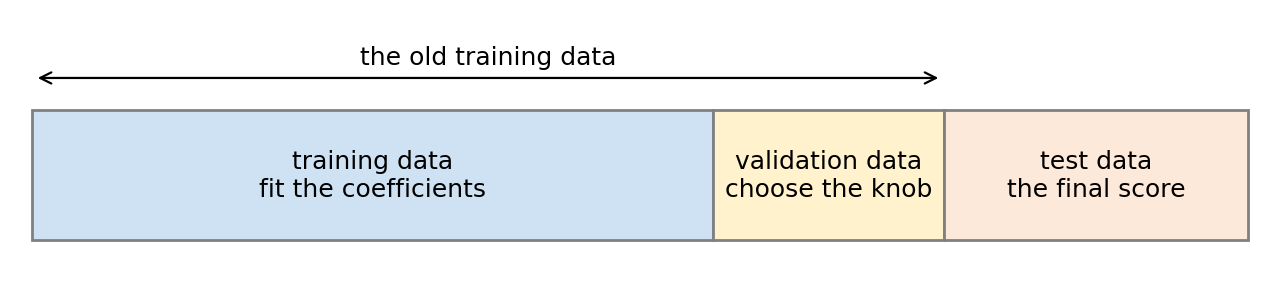

In [24]:
fig, ax = plt.subplots(figsize=(8, 1.6))
parts = [('training data\nfit the coefficients', 0, 56, '#cfe2f3'),
         ('validation data\nchoose the knob', 56, 19, '#fff2cc'),
         ('test data\nthe final score', 75, 25, '#fde9d9')]
for name, start, width, color in parts:
    ax.add_patch(Rectangle((start, 0), width, 1, fc=color, ec='grey'))
    ax.text(start + width / 2, 0.5, name, ha='center', va='center',
            fontsize=9)
ax.annotate('', xy=(75, 1.25), xytext=(0, 1.25),
            arrowprops={'arrowstyle': '<->', 'lw': 0.8})
ax.text(37.5, 1.35, 'the old training data', ha='center', fontsize=9)
ax.set(xlim=(-1, 101), ylim=(-0.2, 1.7))
ax.axis('off')
plt.show()


- The test data touch no decision, so their score is clean: it is the
  error of the finished model on observations it never saw.
- One validation set is a noisy judge. Here it would hold about 19
  observations, and the valley moves when the draw changes.
- The fix: cut the training data into $k$ folds, let each fold be the
  validation set once, and average the $k$ scores. **Cross-validation.**


### Cross-validation: five validation sets instead of one

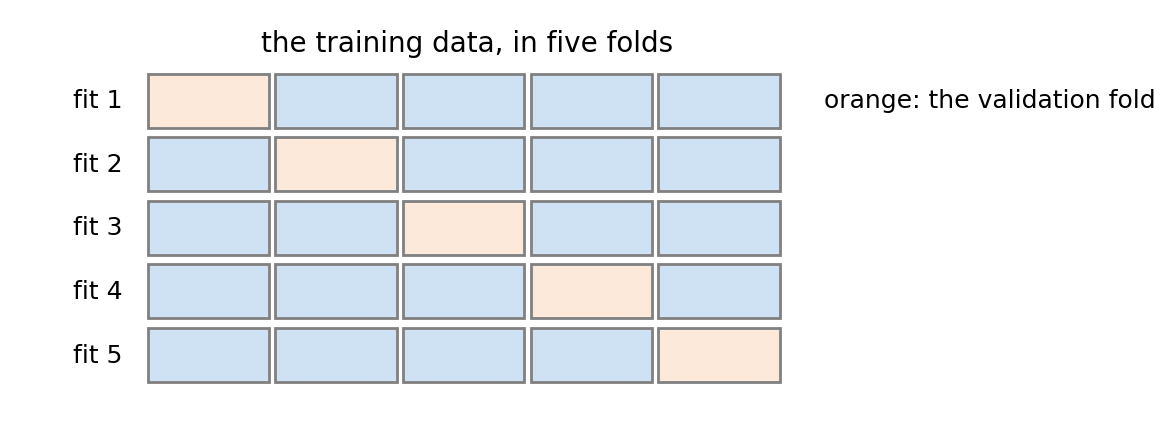

In [25]:
fig, ax = plt.subplots(figsize=(7, 2.6))
for fold in range(5):
    for block in range(5):
        color = '#fde9d9' if block == fold else '#cfe2f3'
        ax.add_patch(Rectangle((block, -fold), 0.95, 0.85, fc=color,
                               ec='grey'))
    ax.text(-0.2, -fold + 0.42, f'fit {fold + 1}', ha='right',
            va='center', fontsize=9)
ax.text(2.5, 1.2, 'the training data, in five folds', ha='center')
ax.text(5.3, 0.42, 'orange: the validation fold', va='center',
        fontsize=9)
ax.set(xlim=(-1, 7.5), ylim=(-4.6, 1.7))
ax.axis('off')
plt.show()

- Five fits, five scores. `cross_val_score(model, X_train, y_train,
  cv=5)` returns the five numbers; their mean is the estimate and their
  spread says how much one split can mislead.
- Each observation is used for fitting four times and for scoring once.
  The test data stay untouched until the end, so the final score is
  clean.
- `GridSearchCV` (Part 8) runs this loop for every value of a knob and
  keeps the value with the best mean.

### The split on the face data

Two parameters cannot memorize 89 observations, but the habit starts
here: fit on
three quarters of the races, score on the rest.

In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)
line = LinearRegression().fit(X_train, y_train)
for name, X_part, y_part in [('train', X_train, y_train),
                             ('test', X_test, y_test)]:
    error = np.sqrt(mean_squared_error(y_part, line.predict(X_part)))
    print(f'{name:5s} n = {len(X_part):3d}   RMSE {error:.3f}')

train n =  89   RMSE 0.265
test  n =  30   RMSE 0.261


- 89 training races, 30 test races. The two errors are the same size,
  0.26: the line generalizes as well as it fits. A line cannot overfit 89
  points; the models below can.

<div class="alert alert-info">

**Key idea.** Fit on some data, score on other data, and compare the
score with the baseline. A model scored on its training data may have
memorized them; a model scored on held-out data has to have learned
something. 

</div>

## Part 4: logistic regression

### Does a voting record reveal the party?

- Lectures 4 to 6 placed every member of the House on the DW-NOMINATE
  scale, a left-to-right score computed from roll-call votes: negative is
  liberal, positive is conservative. The question is whether that one
  number is enough to tell a Democrat from a Republican.
- In the 112th House (2011 to 2012) it is: no Republican sits left of
  any Democrat, so there is nothing to learn. The **90th House** (1967 to
  1968) is the case worth examining, because conservative Southern
  Democrats and liberal Northeastern Republicans met in the middle.
- One observation is one member; the label is the party; the feature is
  the first-dimension score `dwnom1`.

In [27]:
congress = pd.read_csv(RAW / 'congress.csv')
house = congress[(congress['congress'] == 90)
                 & congress['party'].isin(['Democrat', 'Republican'])]
house = house.copy()
house['rep'] = (house['party'] == 'Republican').astype(int)
print(len(house), 'members')
house['rep'].value_counts()

438 members


rep
0    249
1    189
Name: count, dtype: int64

- 249 Democrats and 189 Republicans. `y` is `rep`, 1 for a Republican
  and 0 for a Democrat: a classification task. The baseline is the
  larger class, "Democrat" for every member, 249 / 438 = 0.568.
- The file holds every House from the 80th to the 112th; the first line
  keeps one Congress and drops the handful of members of no party.


### The outcome against the predictor

Every member sits on one of two lines, at 0 or at 1. The dots are
jittered a little so that 438 of them do not pile up.

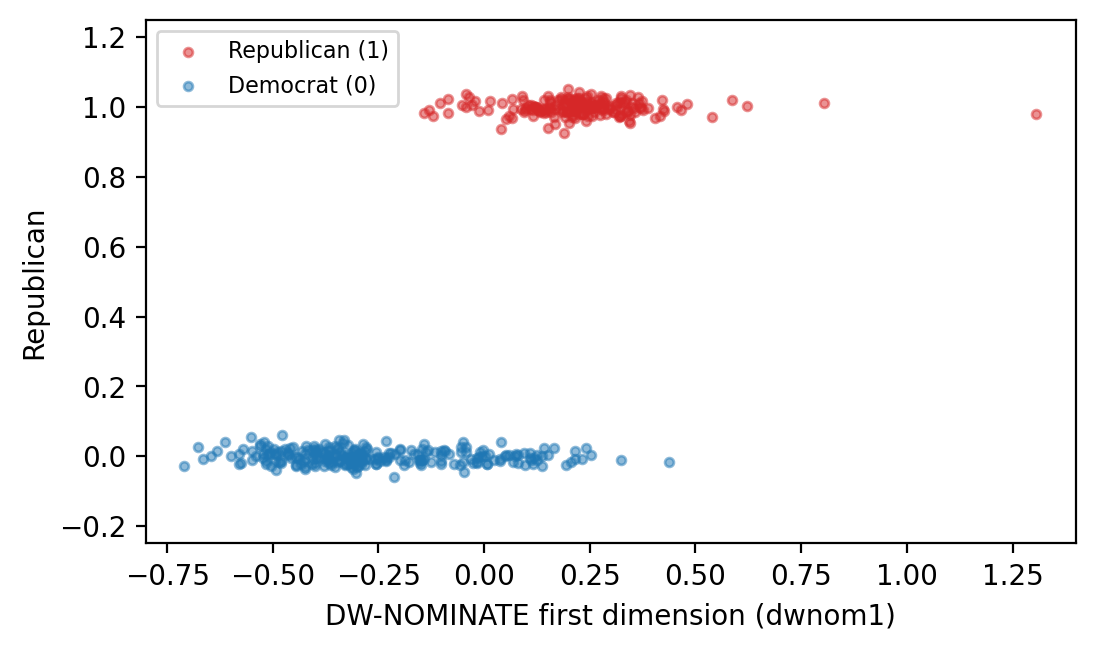

In [28]:
jitter = np.random.default_rng(0).normal(0, 0.02, len(house))

def outcome_plot(ax):
    rep = house['rep'] == 1
    ax.scatter(house.loc[rep, 'dwnom1'], house.loc[rep, 'rep']
               + jitter[rep.values], s=10, alpha=0.5, color='C3',
               label='Republican (1)')
    ax.scatter(house.loc[~rep, 'dwnom1'], house.loc[~rep, 'rep']
               + jitter[~rep.values], s=10, alpha=0.5, color='C0',
               label='Democrat (0)')
    ax.set(xlabel='DW-NOMINATE first dimension (dwnom1)',
           ylabel='Republican', xlim=(-0.8, 1.4), ylim=(-0.25, 1.25))

fig, ax = plt.subplots(figsize=(6, 3.4))
outcome_plot(ax)
ax.legend(fontsize=8)
plt.show()


- Red members at the top, blue at the bottom. Left of −0.2 the top line
  is empty; right of 0.3 the bottom line is nearly empty; between them
  the two lines overlap.
- A model should give, for any score, the **probability** that the member
  is a Republican, a number between 0 and 1.


### A first attempt: the line of Part 2

Fit `LinearRegression` to the 0/1 label and draw it.

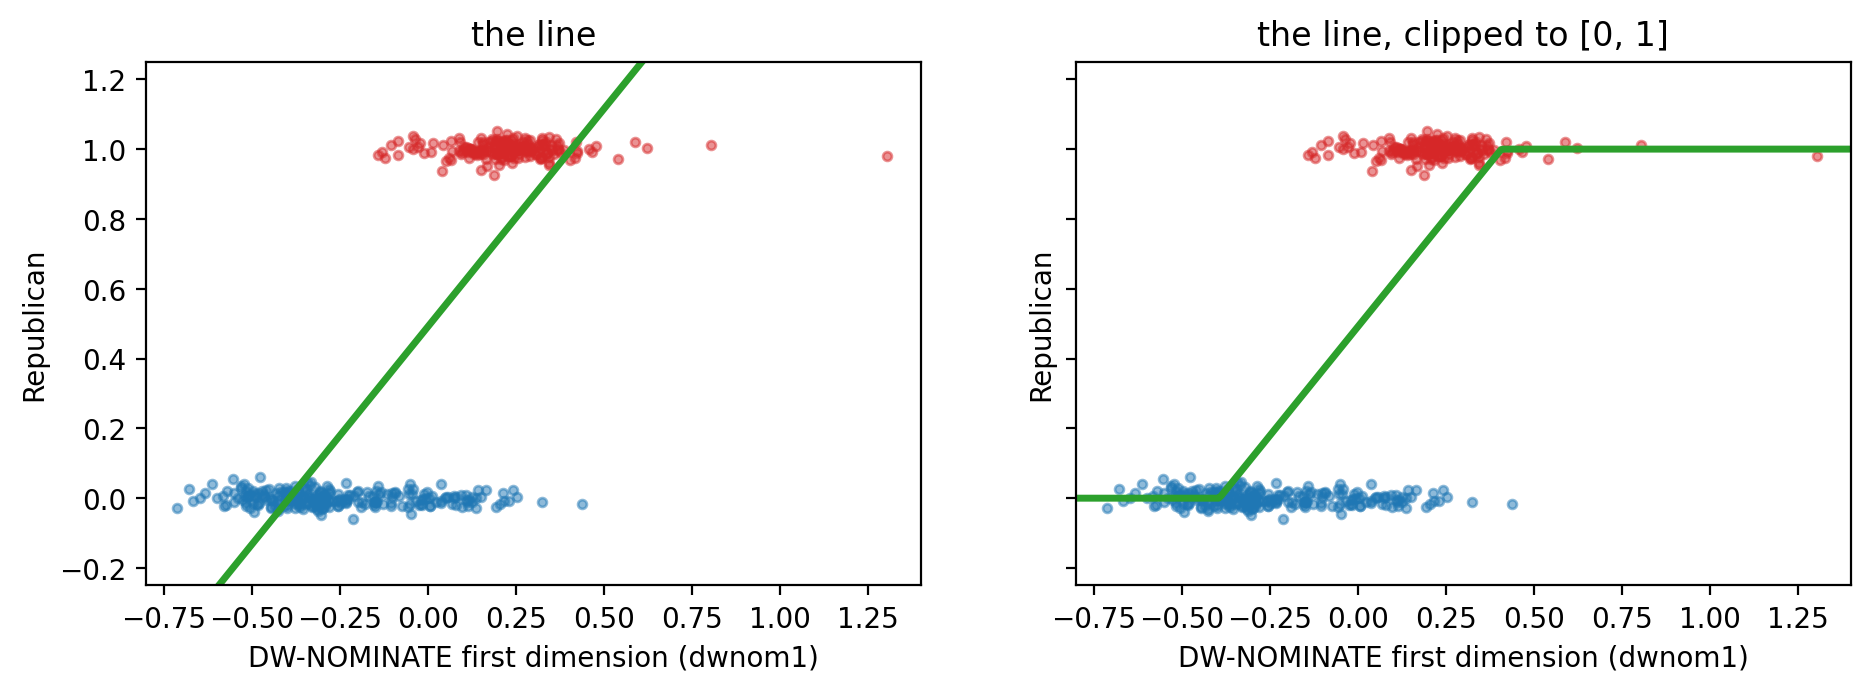

[-0.38  0.49  1.12  2.11]


In [29]:
X = house[['dwnom1']]
y = house['rep']
straight = LinearRegression().fit(X, y)
grid = np.linspace(-0.8, 1.4, 300)
line_out = straight.predict(pd.DataFrame({'dwnom1': grid}))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, fitted, title in [(axes[0], line_out, 'the line'),
                          (axes[1], np.clip(line_out, 0, 1),
                           'the line, clipped to [0, 1]')]:
    outcome_plot(ax)
    ax.plot(grid, fitted, color='C2', lw=2.5)
    ax.set(title=title)
plt.show()
print(straight.predict(pd.DataFrame({'dwnom1': [-0.7, 0, 0.5, 1.3]}))
      .round(2))

- The line gives −0.4 at a score of −0.7 and 2.1 at 1.3. A line has no
  floor and no ceiling, so its outputs cannot be probabilities.
- Clipping the line at 0 and 1 (right) patches the ends but leaves two
  corners where the slope changes at once. Nothing in the data looks
  like that.

### A second attempt: bins and shares

Cut the score into bins of width 0.1. In each bin, the share of members
who are Republicans is the probability we are after, with no model at all.

In [30]:
edges = np.arange(-0.8, 1.41, 0.1)
bins = pd.cut(house['dwnom1'], edges)
by_bin = house.groupby(bins, observed=True)['rep']
shares = by_bin.agg(['mean', 'size'])
shares.round(2).T

dwnom1,"(-0.8, -0.7]","(-0.7, -0.6]","(-0.6, -0.5]","(-0.5, -0.4]","(-0.4, -0.3]","(-0.3, -0.2]","(-0.2, -0.1]","(-0.1, -2.22e-16]","(-2.22e-16, 0.1]","(0.1, 0.2]","(0.2, 0.3]","(0.3, 0.4]","(0.4, 0.5]","(0.5, 0.6]","(0.6, 0.7]","(0.8, 0.9]","(1.3, 1.4]"
mean,0.0,0.0,0.0,0.0,0.0,0.0,0.14,0.3,0.44,0.79,0.92,0.97,0.89,1.0,1.0,1.0,1.0
size,1.0,5.0,22.0,38.0,62.0,36.0,29.00,30.0,32.00,61.00,73.00,35.00,9.00,2.0,1.0,1.0,1.0


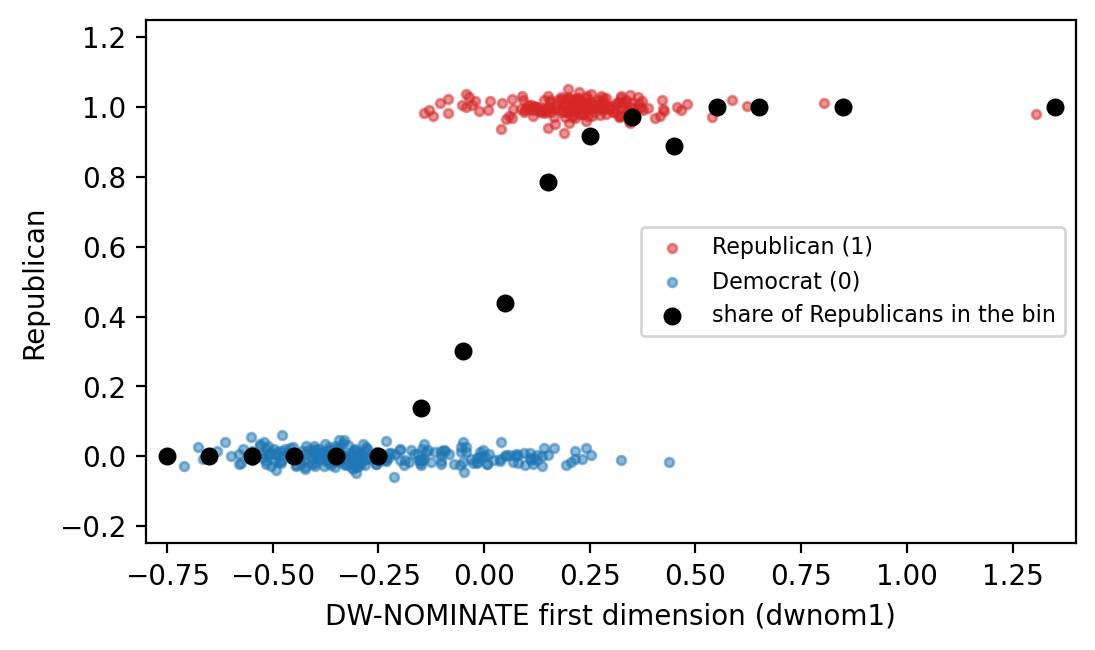

In [31]:
mids = [(a + b) / 2 for a, b in zip(edges[:-1], edges[1:])]
mids = pd.Series(mids, index=pd.cut(mids, edges)).loc[shares.index]
fig, ax = plt.subplots(figsize=(6, 3.4))
outcome_plot(ax)
ax.scatter(mids, shares['mean'], s=30, color='black', zorder=3,
           label='share of Republicans in the bin')
ax.legend(fontsize=8)
plt.show()

- Each black circle is one bin. Left of −0.2 every bin is 0; then 0.14,
  0.30, 0.44, 0.79, 0.92, 0.97; right of 0.4 every bin is 1 but one lone
  member.
- The rise is not a straight line: low and flat, then a climb across
  four bins, then high and flat. An S, read from left to right. A model
  with that shape, fitted to all 438 members at once, would give a
  probability for every score without the steps of the bins.


### The sigmoid

The **logistic function**, or sigmoid, has that S shape and stays between 0
and 1 for every input:

$$\sigma(z) = \frac{1}{1 + e^{-z}}$$

Logistic regression feeds a line into it: $z_i = w_0 + w_1 x_i$, then
$p_i = \sigma(z_i)$ is the probability that $y_i = 1$.

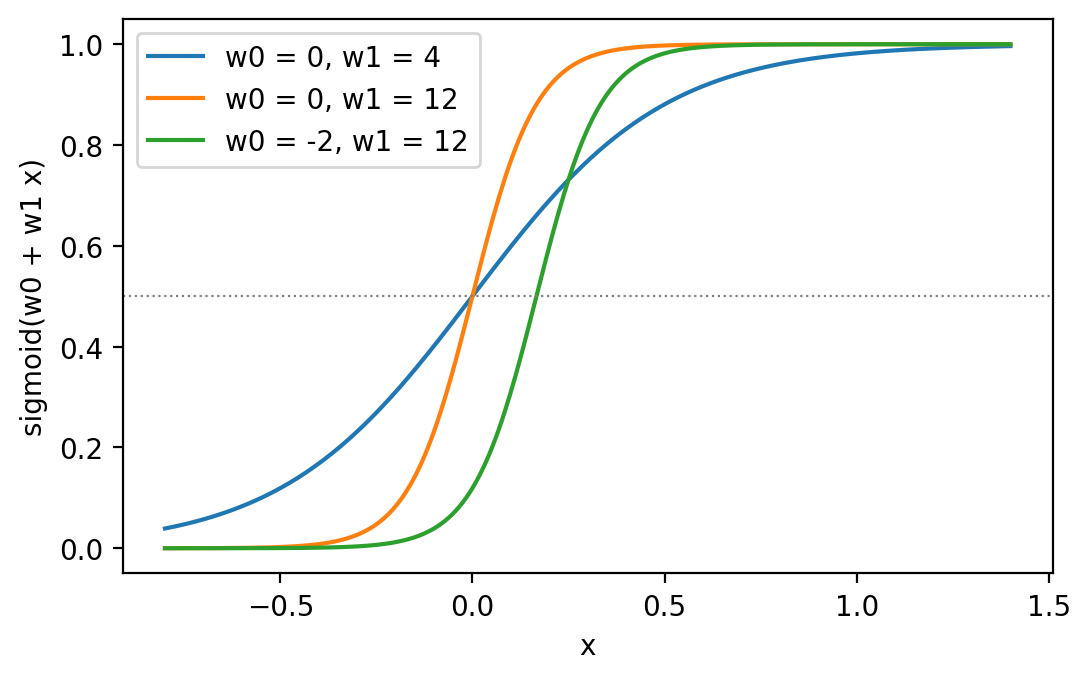

In [32]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

fig, ax = plt.subplots(figsize=(6, 3.6))
for w0, w1 in [(0, 4), (0, 12), (-2, 12)]:
    ax.plot(grid, sigmoid(w0 + w1 * grid),
            label=f'w0 = {w0}, w1 = {w1}')
ax.axhline(0.5, color='grey', lw=0.8, ls=':')
ax.set(xlabel='x', ylabel='sigmoid(w0 + w1 x)')
ax.legend()
plt.show()

- $w_1$ sets the steepness, and its sign sets the direction: positive
  here, because Republicans sit at high scores. $w_0$ slides the curve left
  or right. The curve crosses 0.5 where $w_0 + w_1 x = 0$.
- The inside is a linear regression; the outside turns it into a
  probability. That is the whole model.

### Notation for classification

| Symbol | Where it lives |
|---|---|
| $x_i$ | the column `dwnom1` |
| $y_i \in \{0, 1\}$ | the column `rep`, computed from `party` |
| $z_i = w_0 + w_1 x_i$ | computed: `model.decision_function(X)` |
| $p_i = \sigma(z_i)$ | computed: `model.predict_proba(X)[:, 1]` |
| $\hat y_i = 1$ if $p_i \ge 0.5$, else 0 | computed: `model.predict(X)` |

- `fit` chooses $w_0$ and $w_1$ so that the curve gives the observed
  labels high probability. The error measure is not MSE but one built for
  probabilities; `sklearn` handles it.

### `LogisticRegression`

Split the members as in Part 3, with `stratify` so that both parts hold
the same share of Republicans, then fit.

In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
logit = LogisticRegression()
logit.fit(X_train, y_train)
logit.intercept_.round(3), logit.coef_.round(3)

(array([-0.294]), array([[6.512]]))

In [34]:
shown = X_train.head().copy()
shown['rep'] = y_train.head()
shown['z'] = logit.decision_function(X_train.head()).round(2)
shown['p'] = logit.predict_proba(X_train.head())[:, 1].round(2)
shown['label'] = logit.predict(X_train.head())
shown.insert(0, 'name', house.loc[shown.index, 'name'])
shown

,name,dwnom1,rep,z,p,label
4512,RONAN,-0.505,0,-3.58,0.03,0
4607,BROOMFIELD,0.157,1,0.73,0.67,1
4574,FALLON,-0.221,0,-1.73,0.15,0
4762,SCHNEEBELI,0.344,1,1.95,0.87,1
4668,BRASCO,-0.430,0,-3.09,0.04,0


- $p = \sigma(-0.29 + 6.51 \cdot \texttt{dwnom1})$. The curve crosses 0.5
  at $0.29 / 6.51 = 0.045$: a member scored above 0.045 is more likely
  than not a Republican, by this model.
- Row by row: the stored columns `dwnom1` and `rep`; then `z`, the line;
  `p`, the sigmoid of `z`; `label`, 1 where `p` is at least 0.5. Ronan
  of Illinois, at −0.51, gets 0.03; Broomfield of Michigan, at
  0.16, gets 0.67.


### The estimated sigmoid over the members and the bins


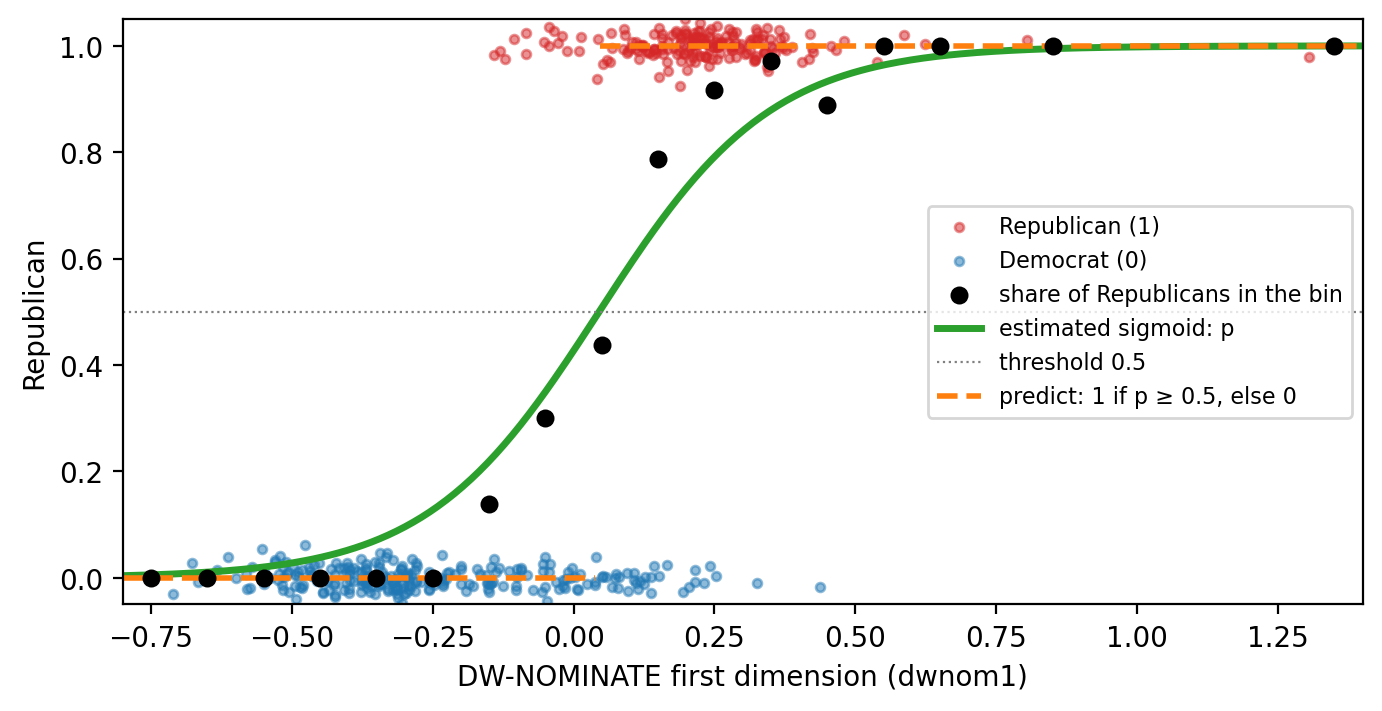

In [35]:
curve = logit.predict_proba(pd.DataFrame({'dwnom1': grid}))[:, 1]
crossing = -logit.intercept_[0] / logit.coef_[0, 0]
left, right = grid < crossing, grid >= crossing

fig, ax = plt.subplots(figsize=(8, 3.8))
outcome_plot(ax)
ax.scatter(mids, shares['mean'], s=30, color='black', zorder=3,
           label='share of Republicans in the bin')
ax.plot(grid, curve, color='C2', lw=2.5, label='estimated sigmoid: p')
ax.axhline(0.5, color='grey', lw=0.8, ls=':', label='threshold 0.5')
ax.plot(grid[left], np.zeros(left.sum()), color='C1', lw=2, ls='--',
        label='predict: 1 if p ≥ 0.5, else 0')
ax.plot(grid[right], np.ones(right.sum()), color='C1', lw=2, ls='--')
ax.set(ylim=(-0.05, 1.05))
ax.legend(fontsize=8, loc='center right')
plt.show()


- The green curve is the estimated sigmoid, $p = \sigma(-0.29 + 6.51 x)$:
  near 0 left of −0.3, near 1 right of 0.4, and the crossing of 0.5 at a
  score of 0.045, where it meets the dotted threshold line. It runs through the bin
  shares and never leaves the unit interval.
- The orange dashed line is what `predict` returns: 0 for every member
  left of the crossing, 1 for every member right of it. Logistic
  regression estimates a probability; the label is that probability cut
  at 0.5. The climb of the S, from 0.14 to 0.97, covers the scores
  between −0.1 and 0.3, where the two parties overlap and the label is
  least certain.


### Accuracy, and `predict_proba` against `predict`

In [36]:
print('baseline', round(y_test.value_counts(normalize=True).max(), 3))
print('train   ', round(logit.score(X_train, y_train), 3))
print('test    ', round(logit.score(X_test, y_test), 3))

baseline 0.573
train    0.881
test     0.918


In [37]:
new = pd.DataFrame({'dwnom1': [-0.3, 0.0, 0.1, 0.3]})
print(logit.classes_)
print(logit.predict_proba(new).round(2))
print(logit.predict(new))

[0 1]
[[0.9  0.1 ]
 [0.57 0.43]
 [0.41 0.59]
 [0.16 0.84]]
[0 0 1 1]


- `score` is accuracy for a classifier: 0.918 on the 110 test members,
  against a baseline of 0.573. One number from the voting record names
  the party of eleven members in twelve.
- `predict_proba` returns one column per class, in the order of
  `classes_`: here $1 - p$ and $p$. `predict` returns the class with the
  larger probability, which is a threshold of 0.5 on $p$.
- A researcher who needs a different threshold applies it to the second
  column. The probability carries more than the label.


### The confusion matrix

Accuracy counts the right answers in the numerator and throws the rest away. The
**confusion matrix** keeps all four kinds of answer. Each test member
falls in one cell: the row is the true party, the column is the model's
label.


In [38]:
pred = logit.predict(X_test)
parties = ['Democrat (0)', 'Republican (1)']
matrix = pd.DataFrame(confusion_matrix(y_test, pred, labels=[0, 1]),
                      index=parties, columns=parties)
matrix.rename_axis(index='true party', columns='model says')


model says,Democrat (0),Republican (1)
true party,,
Democrat (0),58,5
Republican (1),4,43


In [39]:
print('Democrat called Democrat     ', ((y_test == 0) & (pred == 0)).sum())
print('Democrat called Republican   ', ((y_test == 0) & (pred == 1)).sum())
print('Republican called Democrat   ', ((y_test == 1) & (pred == 0)).sum())
print('Republican called Republican ', ((y_test == 1) & (pred == 1)).sum())
print('accuracy', round((pred == y_test).mean(), 3))

Democrat called Democrat      58
Democrat called Republican    5
Republican called Democrat    4
Republican called Republican  43
accuracy 0.918


- The diagonal holds the right answers: 58 Democrats called Democrat,
  43 Republicans called Republican. Off the diagonal are the misses:
  5 Democrats called Republican, 4 Republicans called Democrat.
- Each cell counts the rows where two conditions hold, so `&` and
  `.sum()` compute it by hand. 
- `confusion_matrix(y_test, pred, labels=[0, 1])` computes all four at once.
- Accuracy is the diagonal over the total: (58 + 43) / 110 = 0.918. The
  matrix says where the 9 misses are; the accuracy does not.

### The pitfall: imbalanced classes

Suppose there is another model, a quite lazy one, that answers "Democrat" for every member.

In [40]:
always_dem = np.zeros(len(y_test), dtype=int)
matrix = pd.DataFrame(
    confusion_matrix(y_test, always_dem, labels=[0, 1]),
    index=parties, columns=parties)
print('accuracy', round((always_dem == y_test).mean(), 3))
matrix.rename_axis(index='true party', columns='model says')


accuracy 0.573


model says,Democrat (0),Republican (1)
true party,,
Democrat (0),63,0
Republican (1),47,0


- In this lazy model, the accuracy is 0.573.
- Democrats are 57 percent of this House, so the lazy model scores 0.57.
- However, imagine if in data where one class is 95 percent of the rows, 
  the same lazy model would score 0.95, and a reader who sees only the 
  accuracy would call it a good model. 
- This is why we often shouldn't only care about accuracy (continue on this in Part 6).

### `LogisticRegression`: what to write

| Goal | Write | Returns |
|---|---|---|
| Create the model | `model = LogisticRegression(max_iter=2000)` | an unfitted model |
| Fit it | `model.fit(X_train, y_train)` | the model, with `coef_` and `intercept_` |
| The line $z$ | `model.decision_function(X)` | one number per row |
| Probabilities | `model.predict_proba(X)` | one column per class, in `model.classes_` order |
| Labels | `model.predict(X)` | the class with the largest probability |
| Accuracy | `model.score(X_test, y_test)` | share of rows labeled right |
| The four cells | `confusion_matrix(y_test, model.predict(X_test), labels=[0, 1])` | a 2 × 2 array, true class by row, label by column |

`max_iter=2000` gives the fitting routine enough steps to settle; the
default 100 can stop early and warn on wider tables.

## Part 5: the papers, and k-nearest neighbors

### Back to the question

- Known rows: Hamilton's 51 papers and Madison's 14. Labels to learn from
  and to test on.
- Unknown rows: the 12 papers both men claimed. No label, so no score. A
  model may label them only after it has passed on the known rows.
- The label is the author, so this is classification. Three classifiers
  will try, on more than one representation of the text.

### Read the papers and label the authors

The lecture 12 cells, with `paper` in place of `essay`.

In [41]:
rows = []
for n in range(1, 86):
    path = RAW / 'federalist' / f'fp{n:02d}.txt'
    rows.append({'paper': n,
                 'text': path.read_text(encoding='utf-8')})
papers = pd.DataFrame(rows)

authors = {
    'Hamilton': ([1, 6, 7, 8, 9, 11, 12, 13, 15, 16, 17]
                 + list(range(21, 37)) + [59, 60, 61]
                 + list(range(65, 86))),
    'Madison': [10, 14] + list(range(37, 49)),
    'Jay': [2, 3, 4, 5, 64],
    'Joint': [18, 19, 20],
    'Disputed': list(range(49, 59)) + [62, 63],
}
label = {n: author for author, ns in authors.items() for n in ns}
papers['author'] = papers['paper'].map(label)
author = papers.set_index('paper')['author']
text = papers.set_index('paper')['text']
author.value_counts()

author
Hamilton    51
Madison     14
Disputed    12
Jay          5
Joint        3
Name: count, dtype: int64

### One matrix for the whole lecture

The TF-IDF matrix of lecture 12, with one change: the stop list stays off.
Lecture 12 showed that the list removes `upon`, `on`, `while`, and `there`,
the words that tell the two writers apart.

In [42]:
tfidf_vec = TfidfVectorizer(min_df=2)
tfidf = pd.DataFrame(tfidf_vec.fit_transform(papers['text']).toarray(),
                     columns=tfidf_vec.get_feature_names_out(),
                     index=papers['paper'])
tfidf.shape

(85, 5424)

- 85 rows, one per paper, and 5,424 columns, one per word that appears in
  at least two papers. `.toarray()` turns the sparse matrix into a dense
  one so that it fits in a DataFrame with the words as column names and
  the paper numbers as the index.
- The vocabulary is built from all 85 texts without reading any label.
  The split below still holds the labels of the test papers out.

### The ten style words are columns of that matrix

Mosteller and Wallace (1963) worked from function words, the words a writer
uses without thinking. Select ten of them; nothing is rebuilt.

In [43]:
style_words = ['upon', 'whilst', 'while', 'there', 'on', 'although',
               'always', 'commonly', 'consequently', 'enough']
style = tfidf[style_words]
style.join(author).groupby('author').mean().round(3)

,upon,whilst,while,there,on,although,always,commonly,consequently,enough
author,,,,,,,,,,
Disputed,0.001,0.007,0.000,0.010,0.057,0.004,0.002,0.000,0.006,0.000
Hamilton,0.031,0.000,0.004,0.026,0.024,0.000,0.006,0.003,0.000,0.005
Jay,0.001,0.000,0.004,0.009,0.041,0.012,0.012,0.003,0.010,0.000
Joint,0.004,0.005,0.000,0.005,0.045,0.000,0.004,0.003,0.000,0.003
Madison,0.002,0.006,0.000,0.007,0.053,0.004,0.002,0.000,0.006,0.000


- Hamilton's papers weight `upon` at 0.031 on average, Madison's at
  0.002; `on` runs the other way, 0.024 against 0.053. The disputed row
  sits with Madison's on both.
- The values are TF-IDF weights, between 0 and about 0.08, not counts.
  Scale matters later.

### Baseline and split

Split the 65 known papers once. Every representation below uses the same
training papers and the same test papers, selected by paper number.

In [44]:
known_ids = author.index[author.isin(['Hamilton', 'Madison'])]
disputed_ids = author.index[author == 'Disputed']
X = style.loc[known_ids]
y = author.loc[known_ids]
print('baseline', round(y.value_counts(normalize=True).max(), 3))
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print(y_train.value_counts().to_dict(), y_test.value_counts().to_dict())

baseline 0.785
{'Hamilton': 38, 'Madison': 10} {'Hamilton': 13, 'Madison': 4}


- The baseline is 51 / 65 = 0.785: "Hamilton" for every paper. A model
  must beat it by finding Madison's papers, and 10 training papers is a
  small number to learn a writer from.
- `stratify=y` puts 4 of the 14 Madison papers in the test data. Without
  it, a draw could leave one or none.

### Classifier 1: k-nearest neighbors

Two columns first, `to` and `by`, so that the model can be drawn. Both
writers use both words in every paper, at different rates: two of
Mosteller and Wallace's marker words. (`upon` alone would settle the
matter and leave nothing to draw.) For a new paper:

1. Find the $k$ training papers whose two weights are **closest** to the
   new paper's.
2. Answer the most common label among those $k$ papers.

Closest means the ordinary distance between two papers:
$\sqrt{(u_1 - v_1)^2 + (u_2 - v_2)^2}$. $k$ is our choice.

In [45]:
two = ['to', 'by']
pair_train = tfidf.loc[X_train.index, two]
pair_test = tfidf.loc[X_test.index, two]
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(pair_train, y_train)
new_paper = tfidf.loc[[49], two]
print(knn.predict(new_paper))
distance, position = knn.kneighbors(new_paper)
pair_train.iloc[position[0]].assign(author=y_train.iloc[position[0]],
                                    distance=distance[0].round(4))

['Madison']


,to,by,author,distance
paper,,,,
84,0.235129,0.050643,Hamilton,0.0111
11,0.245258,0.059098,Hamilton,0.0151
42,0.231143,0.077885,Madison,0.0173
46,0.210281,0.051952,Madison,0.0217
37,0.233925,0.083545,Madison,0.0233


- Paper 49, the first disputed paper, gets the label Madison by three
  votes to two: papers 42, 46, and 37 are Madison's, 84 and 11 are
  Hamilton's.
- `to` and `by` are not among the ten style columns, so the pair comes
  from `tfidf`, the full matrix, for the same training and test papers.
- `fit` stores the training data; the work happens in `predict`, which
  searches for the neighbors. `kneighbors` shows them.

### What the model looks like: the decision boundary

Ask the model to label every point of a grid and color the regions. Points
are the training papers.

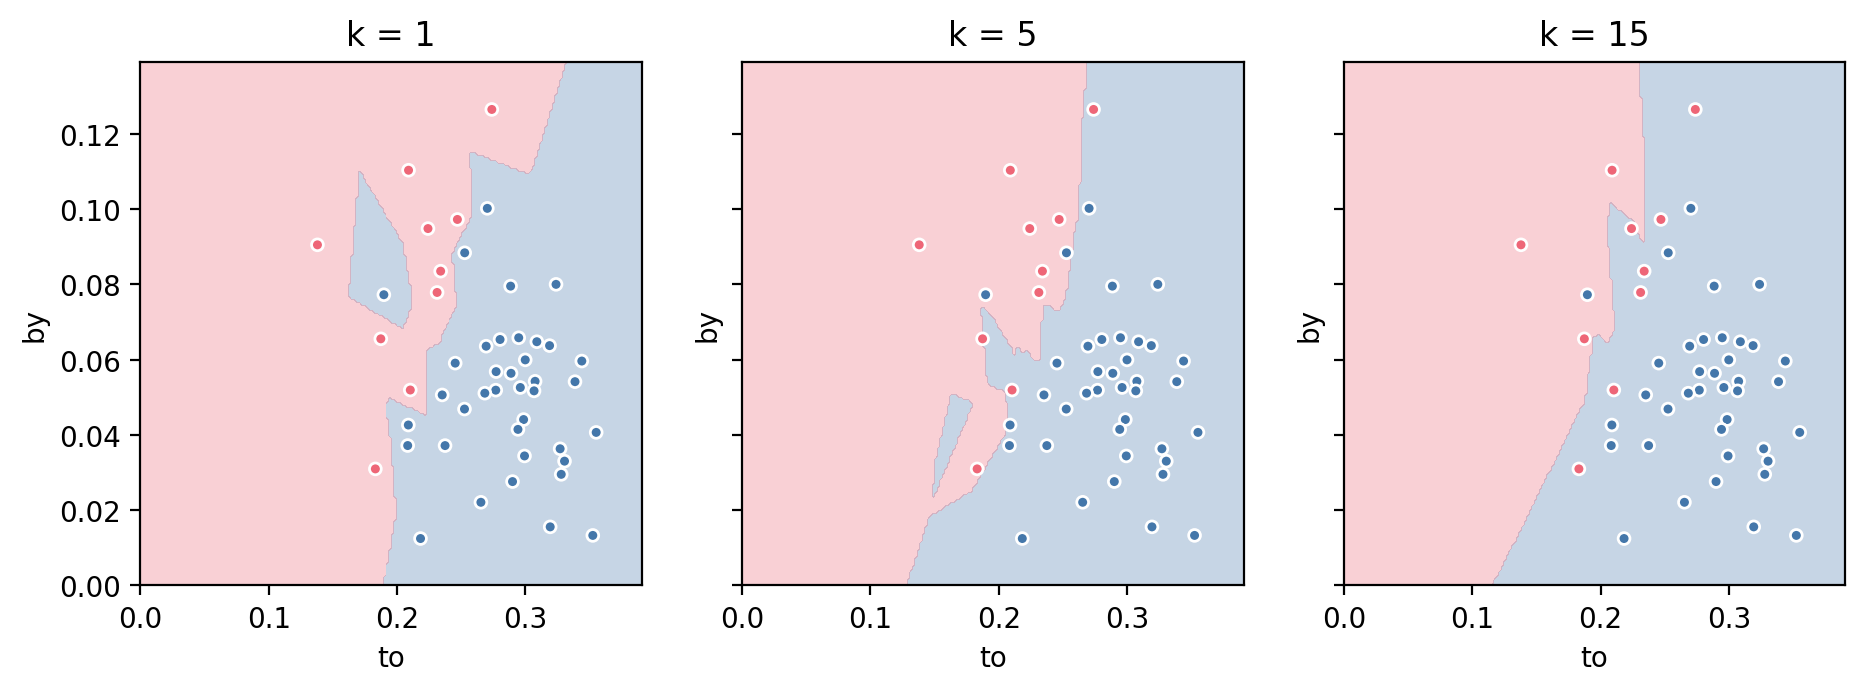

In [46]:
palette = ListedColormap(['#4477aa', '#ee6677'])
classes = ['Hamilton', 'Madison']

def draw_boundary(model, cols, ax, title):
    top = pair_train.max() * 1.1
    g0, g1 = np.meshgrid(np.linspace(0, top.iloc[0], 200),
                         np.linspace(0, top.iloc[1], 200))
    grid = pd.DataFrame({cols[0]: g0.ravel(), cols[1]: g1.ravel()})
    labels = pd.Categorical(model.predict(grid), categories=classes)
    ax.contourf(g0, g1, labels.codes.reshape(g0.shape),
                levels=[-0.5, 0.5, 1.5], cmap=palette, alpha=0.3)
    point_codes = pd.Categorical(y_train, categories=classes).codes
    ax.scatter(pair_train[cols[0]], pair_train[cols[1]], c=point_codes,
               cmap=palette, vmin=0, vmax=1, s=18, edgecolors='white')
    ax.set(title=title, xlabel=cols[0], ylabel=cols[1])

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, k in zip(axes, [1, 5, 15]):
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(pair_train, y_train)
    draw_boundary(knn_k, two, ax, f'k = {k}')
plt.show()

- Blue is Hamilton, red Madison. Madison uses `to` less (0.22 against
  0.28 on average) and `by` more (0.08 against 0.05), so his papers sit
  toward the upper left, inside the edge of Hamilton's cloud.
- With $k = 1$ the edge follows single papers: a jagged line, with an
  island of blue inside the red. With $k = 5$ the island is gone and the
  edge is a smooth curve with one bay. With $k = 15$ the
  edge is close to a straight line, and the Madison papers inside
  Hamilton's cloud are given up.

### Training accuracy, test accuracy, and the five folds

In [47]:
for k in [1, 5, 15]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    folds = cross_val_score(knn_k, pair_train, y_train, cv=5)
    knn_k.fit(pair_train, y_train)
    print(f'k = {k:>2}   train {knn_k.score(pair_train, y_train):.3f}'
          f'   test {knn_k.score(pair_test, y_test):.3f}'
          f'   five folds {folds.mean():.3f}')

k =  1   train 1.000   test 0.824   five folds 0.871
k =  5   train 0.917   test 0.765   five folds 0.873
k = 15   train 0.833   test 0.765   five folds 0.791


- $k = 1$ scores 1.0 on the training data, as it must: the nearest
  training paper to a training paper is itself. The folds, 0.87, are the
  score that counts.
- $k = 1$ and $k = 5$ tie across the folds at 0.87; $k = 15$ falls to
  0.79, near the baseline, because 15 neighbors rarely hold a Madison
  majority. On the 17 test papers $k = 5$ scores the baseline itself,
  0.76 (13 of the 17 are Hamilton's). Two words let us see a model; they
  do not carry one. We keep $k = 5$ for the ten columns below: smooth
  enough to ignore a stray paper, small enough that 10 Madison papers
  can still win a vote.

### ❓ Question

The training data hold 38 Hamilton and 10 Madison papers. With $k = 48$,
what does the model answer for every paper, and what is its accuracy?

<details><summary>Answer</summary>

**Hamilton for every paper, and the baseline.** The 48 nearest papers are
all the training papers, and 38 of them are Hamilton's, so the vote is
the same for any input. A large $k$ turns kNN into the majority rule;
somewhere between 5 and 48 the Madison papers stop being able to win a
vote. That is why $k$ is chosen on the training data.

</details>

### All ten columns

The same model on the ten style columns: `X_train` and `X_test` from the
split above. Nothing changes in the code but the width of the table.


In [48]:
knn10 = KNeighborsClassifier(n_neighbors=5)
knn10.fit(X_train, y_train)
print('train', round(knn10.score(X_train, y_train), 3),
      '  test', round(knn10.score(X_test, y_test), 3))


train 0.979   test 0.941


### The confusion matrix again

Rows are the true author, columns the model's label, as in Part 4.


In [49]:
pred = knn10.predict(X_test)
matrix = pd.DataFrame(confusion_matrix(y_test, pred, labels=classes),
                      index=classes, columns=classes)
matrix.rename_axis(index='true author', columns='model says')

model says,Hamilton,Madison
true author,,
Hamilton,12,1
Madison,0,4


In [50]:
right = (matrix.loc['Hamilton', 'Hamilton']
         + matrix.loc['Madison', 'Madison'])
print('accuracy by hand', round(right / matrix.values.sum(), 3))
print('score           ', round(knn10.score(X_test, y_test), 3))

accuracy by hand 0.941
score            0.941


- Ten columns beat two words: test accuracy 0.94 against 0.76, with the
  same $k$. The distance now runs over `upon`, `on`, and `there`, the
  words that tell the writers apart.
- The matrix: 12 of the 13 Hamilton test papers called Hamilton, all 4
  Madison papers called Madison, one Hamilton paper called Madison.
  Accuracy is the diagonal over the total, (12 + 4) / 17 = 0.941, the
  number `score` returns.
- The baseline is 0.785: a model that said Hamilton for every paper
  would show an empty Madison column and 13 of 17 right. This matrix
  shows the 4 Madison papers found, which the accuracy alone cannot.


### kNN: what to write

| Goal | Write |
|---|---|
| Create and fit | `knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)` |
| Labels, accuracy | `knn.predict(X_new)`, `knn.score(X_test, y_test)` |
| The neighbors of a row | `knn.kneighbors(X_new)` returns distances and positions |
| Five scores for one $k$ | `cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train, cv=5)` |
| The four cells | `confusion_matrix(y_test, knn.predict(X_test), labels=classes)` |


## Part 6: evaluation

### Fishing with a net

- A lake holds fish and other things: weeds, boots, rocks. You cast a net
  and pull it up. What came up is what you **retrieved**; the fish in the
  lake are what is **relevant**.
- Two questions about the catch, and they are different questions:
  of what the net brought up, how much is fish? Of the fish in the lake,
  how many did the net catch?
- Every classifier with a yes-or-no label is a net. The positive class is
  the fish.

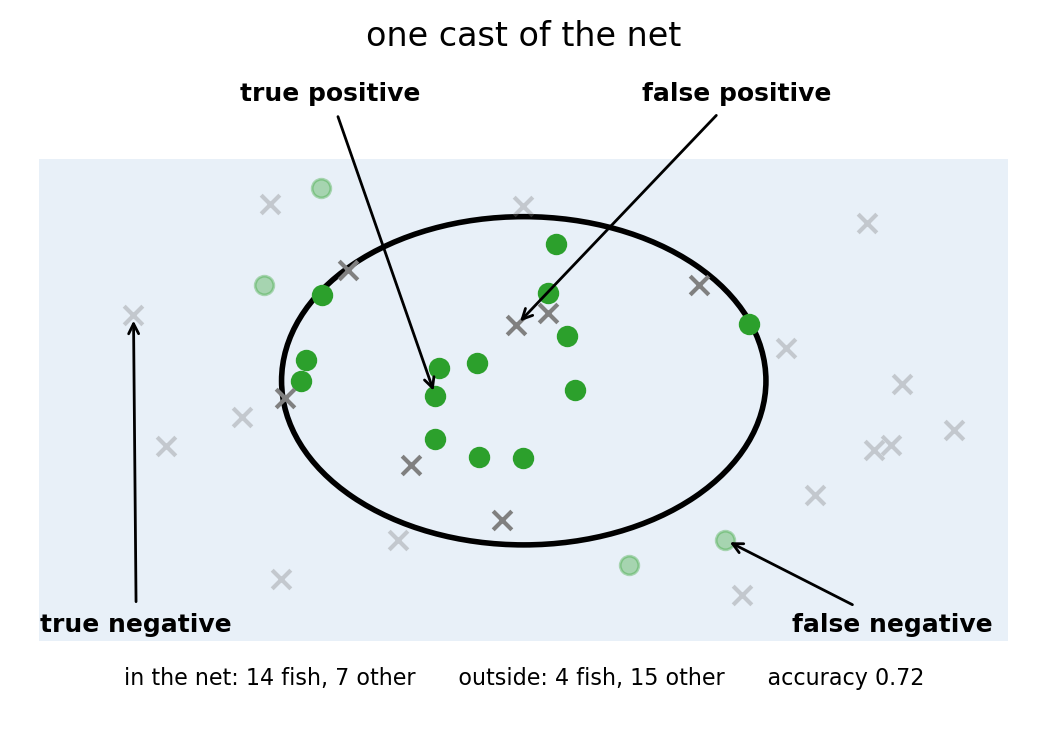

In [51]:
def catch_figure(ax, width, height, title):
    rng = np.random.default_rng(4)
    fish = rng.normal([5, 2.7], [1.4, 0.9], size=(18, 2))
    fish = fish.clip([0.3, 0.3], [9.7, 4.7])
    other = rng.uniform([0.3, 0.3], [9.7, 4.7], size=(22, 2))
    ax.add_patch(Rectangle((0, 0), 10, 5, fc='#e8f0f8', ec='none'))
    ax.add_patch(Ellipse((5, 2.7), width, height, fc='none',
                         ec='black', lw=2))
    inside = lambda p: ((p[:, 0] - 5) / (width / 2)) ** 2 \
        + ((p[:, 1] - 2.7) / (height / 2)) ** 2 < 1
    counts = {}
    for pts, marker, color, name in [(fish, 'o', 'C2', 'fish'),
                                     (other, 'x', 'grey', 'other')]:
        keep = inside(pts)
        counts[name] = (keep.sum(), (~keep).sum())
        ax.scatter(*pts[keep].T, marker=marker, color=color, s=45,
                   zorder=3)
        ax.scatter(*pts[~keep].T, marker=marker, color=color, s=45,
                   zorder=3, alpha=0.35)
    tp, fn = counts['fish']
    fp, tn = counts['other']
    accuracy = (tp + tn) / (tp + fp + fn + tn)
    ax.text(5, -0.45, f'in the net: {tp} fish, {fp} other'
            f'      outside: {fn} fish, {tn} other'
            f'      accuracy {accuracy:.2f}', ha='center',
            fontsize=8)
    ax.set(xlim=(-0.2, 10.2), ylim=(-0.7, 6.0), title=title)
    ax.axis('off')
    return fish, other, inside

fig, ax = plt.subplots(figsize=(6.5, 4.2))
fish, other, inside = catch_figure(ax, 5.0, 3.4, 'one cast of the net')
fish_in, fish_out = fish[inside(fish)], fish[~inside(fish)]
other_in, other_out = other[inside(other)], other[~inside(other)]
examples = [(fish_in[0], 'true positive', (3.0, 5.6)),
            (other_in[0], 'false positive', (7.2, 5.6)),
            (fish_out[fish_out[:, 0].argmax()], 'false negative',
             (8.8, 0.1)),
            (other_out[other_out[:, 0].argmin()], 'true negative',
             (1.0, 0.1))]
for point, name, place in examples:
    ax.annotate(name, xy=point, xytext=place, ha='center', fontsize=9,
                fontweight='bold', arrowprops={'arrowstyle': '->'})
plt.show()

- Green circles are fish; grey crosses are weeds, boots, and rocks. They
  are mixed through the lake, and the fish school near the middle. The
  oval is the net.
- Inside the net: **true positives** (fish, caught) and **false positives** (not fish, caught). 
- Outside: **false negatives** (fish, missed) and **true negatives** (not fish, left in the lake). 
- True or false says whether that decision was right. 
- Positive or negative says whether we catch it in the net.
- These are the four cells of the confusion matrix.
- Accuracy is the two right decisions (true positive and true negatives) over everything in the lake:
  (14 + 15) / 40 = 0.72.

### Recall and precision


- **Precision** answers: how much of what I retrieved is relevant?
  -  This is measuring: how many of the items I caught are actually a fish.

$$\text{precision} = \frac{TP}{TP + FP}
= \frac{\text{fish in the net}}{\text{everything in the net}}
$$


- **Recall** answers: how much of what is relevant did I retrieve?
  - This is measuring: out of all the fish in the lake, how many did I catch.


$$
\text{recall} = \frac{TP}{TP + FN}
= \frac{\text{fish in the net}}{\text{fish in the lake}}
$$


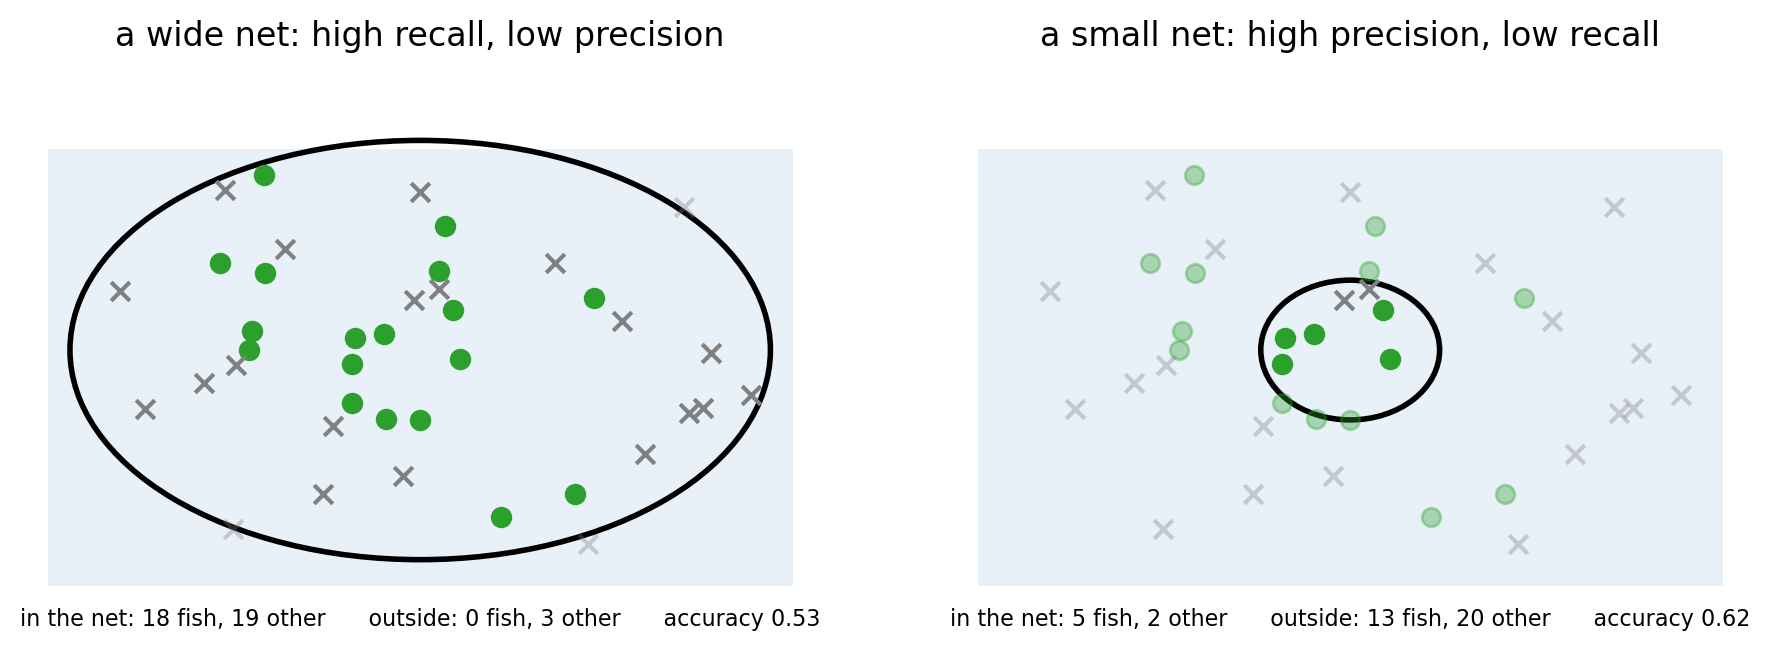

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
catch_figure(axes[0], 9.4, 4.8,
             'a wide net: high recall, low precision')
catch_figure(axes[1], 2.4, 1.6,
             'a small net: high precision, low recall')
plt.show()

- The wide net brings up all 18 fish and 19 other things: recall 1.0,
  precision 0.49, accuracy 0.52.
- The small net, cast on the school, brings up 7 things, 5 of them fish,
  and leaves 13 fish in the lake: precision 0.71, recall 0.28, accuracy
  0.62.
- One number can be made perfect by a useless net: label everything
  positive for recall 1.0, or label the single surest case for precision
  1.0. 
- We should read the two together.

### Should we aim for precision or recall

- **Recall first** when a miss is costly: a screening test for a tumor
  should catch every case and accept some false alarms, because a missed
  case can kill and a false alarm costs a second test.
- **Precision first** when a false alarm is costly: a spam filter should
  move a message to the junk folder only when it is sure, because a real
  message lost in the junk folder costs more than one spam in the inbox.

### Second pass: the net cast on the papers

Madison is the positive class, the fish. Fit logistic regression on the
ten columns behind a `StandardScaler`, which rescales every column to
mean 0 and spread 1, fitted on the training rows: `on` reaches 0.08 and
`commonly` 0.01, and the penalty inside `LogisticRegression` treats every
coefficient alike, so the columns should share a scale. `make_pipeline`
puts the scaler in front of the model, so `fit` and `predict` run both
steps.


In [53]:
logit10 = make_pipeline(StandardScaler(),
                        LogisticRegression(max_iter=2000))
logit10.fit(X_train, y_train)
matrix = pd.DataFrame(
    confusion_matrix(y_test, logit10.predict(X_test), labels=classes),
    index=classes, columns=classes)
matrix.rename_axis(index='true author', columns='model says')

model says,Hamilton,Madison
true author,,
Hamilton,12,1
Madison,0,4


- The four cells of Part 4, with the authors as the classes. Read
  Madison's row for recall: 4 of 4 caught. Read Madison's column for
  precision: 4 of the 5 papers called Madison's are his. Accuracy is the
  diagonal over the total, (12 + 4) / 17 = 0.94.
- `classification_report` computes both for each class, with `support`,
  the number of test papers of that class.


In [54]:
print(classification_report(y_test, logit10.predict(X_test)))

              precision    recall  f1-score   support

    Hamilton       1.00      0.92      0.96        13
     Madison       0.80      1.00      0.89         4

    accuracy                           0.94        17
   macro avg       0.90      0.96      0.92        17
weighted avg       0.95      0.94      0.94        17



- For Madison: recall 1.00, precision 0.80. The wide net: it caught all
  four and one of Hamilton's with them. `f1-score` is the harmonic mean
  of the two; `accuracy` is the 0.94 that `score` returns.
- The report also gives Hamilton's row, where the one false positive for
  Madison is a false negative: recall 0.92.

In [55]:
knn15 = make_pipeline(StandardScaler(),
                      KNeighborsClassifier(n_neighbors=15))
knn15.fit(X_train, y_train)
print(classification_report(y_test, knn15.predict(X_test)))

              precision    recall  f1-score   support

    Hamilton       0.87      1.00      0.93        13
     Madison       1.00      0.50      0.67         4

    accuracy                           0.88        17
   macro avg       0.93      0.75      0.80        17
weighted avg       0.90      0.88      0.87        17



- kNN with $k = 15$ behind the same scaler: recall 0.50 and precision
  1.00 for Madison. Every paper it called Madison's was, and it missed
  two of the four: the small net. Its accuracy, 0.88, hides that it
  found only half of what we are after.

<div class="alert alert-info">

**Key idea.** Report a classifier with three things: the baseline, the
accuracy on rows the fit never saw, and the recall and precision of the
class the question is about. A score above the baseline can still miss
half of what the question asks for.

</div>


## Part 7: decision trees

### One question at a time

A decision tree sorts papers by asking yes-or-no questions, one column
at a time. Each question compares one column with a cutoff: is the
weight of `to` at most 0.235? The answer sends the paper down the left
branch or the right one. At the end of the branch, the paper receives
the majority label of the training papers that ended there. 

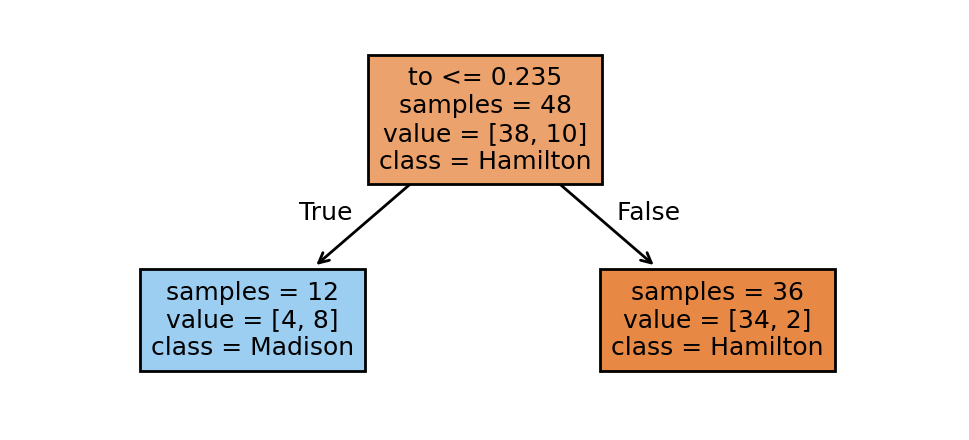

In [56]:
tree1 = DecisionTreeClassifier(max_depth=1, random_state=0)
tree1.fit(pair_train, y_train)
fig, ax = plt.subplots(figsize=(6, 2.6))
plot_tree(tree1, feature_names=two, class_names=tree1.classes_,
          filled=True, impurity=False, fontsize=9, ax=ax)
plt.show()

- `max_depth=1` allows one question. `samples`
  is the number of training papers that reach the box, `value` their
  counts by author in the order of `classes_` (Hamilton, Madison), and
  `class` the majority among them.
- The question is true for 12 papers, 4 by Hamilton and 8 by Madison, so
  the left branch answers Madison. It is false for 36 papers, 34 by
  Hamilton, so the right branch answers Hamilton.
- The fit tries every column and every cutoff and keeps the question
  that sorts the authors best. `random_state=0` fixes which question
  wins when two sort equally well.

### Depth of the tree

`max_depth` is the largest number of questions a paper can be asked.
The same two columns with one, two, and three questions allowed.

depth 1   leaves 2   train 0.875   test 0.765
depth 2   leaves 4   train 0.938   test 0.824
depth 3   leaves 7   train 0.958   test 0.824


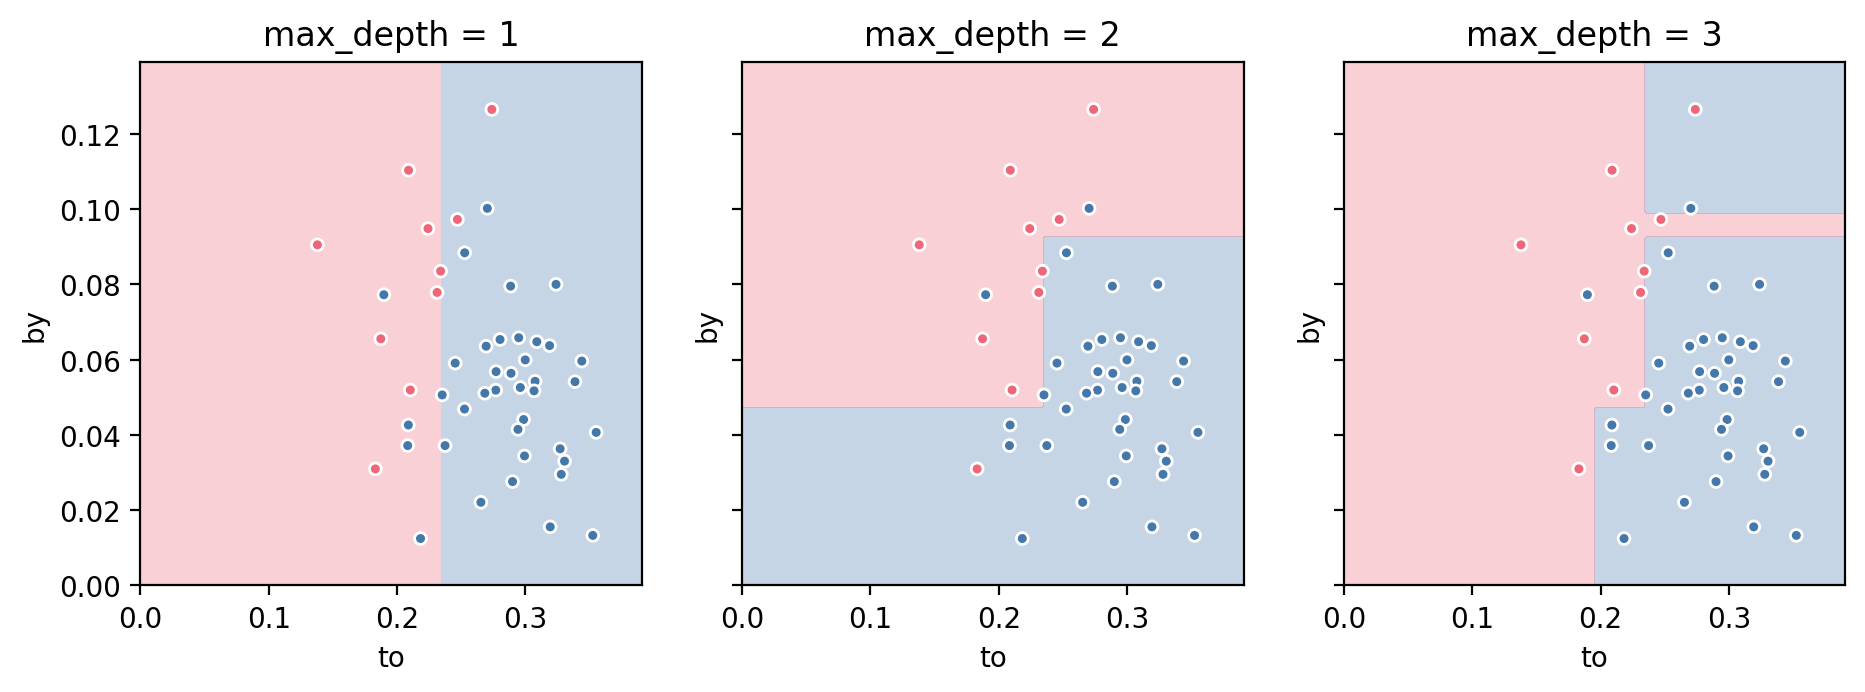

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, depth in zip(axes, [1, 2, 3]):
    tree_d = DecisionTreeClassifier(max_depth=depth, random_state=0)
    tree_d.fit(pair_train, y_train)
    draw_boundary(tree_d, two, ax, f'max_depth = {depth}')
    print(f'depth {depth}   leaves {tree_d.get_n_leaves()}'
          f'   train {tree_d.score(pair_train, y_train):.3f}'
          f'   test {tree_d.score(pair_test, y_test):.3f}')
plt.show()

- Each question splits one region of the plane in two with a straight
  cut: vertical for a question about `to`, horizontal for one about `by`.
  Depth 1 is one vertical cut at `to` = 0.235; papers to its left are
  labeled Madison. Depth 2 asks a second question, about `by`, on each
  side of that cut: four regions. Depth 3 asks a third: seven regions,
  two of which enclose a single training paper.
- Training accuracy rises with the depth: 0.88, 0.94, 0.96. Test
  accuracy: 0.76, 0.82, 0.82. The regions added at depth 3 fit single
  training papers and do not help on the test papers. This is the
  pattern of the training and test curves in Part 3, with `max_depth` in
  the role of the polynomial degree.

### The tree on all ten columns

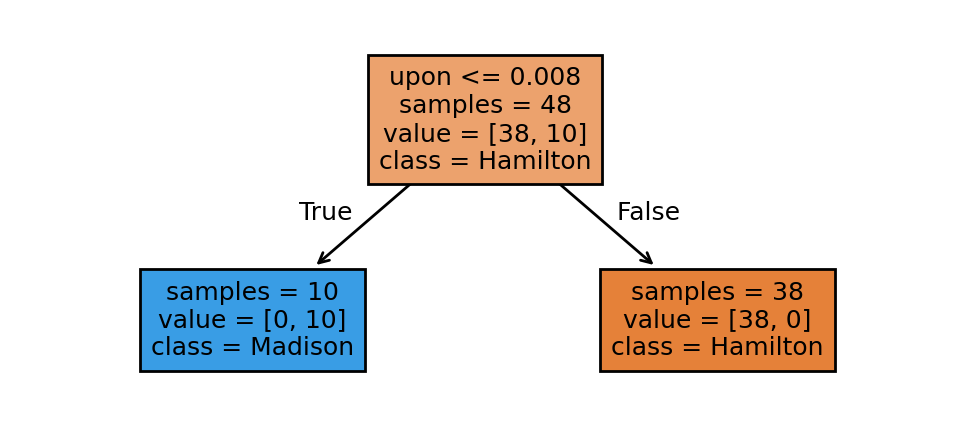

depth 1   train 1.0   test 0.941
              precision    recall  f1-score   support

    Hamilton       0.93      1.00      0.96        13
     Madison       1.00      0.75      0.86         4

    accuracy                           0.94        17
   macro avg       0.96      0.88      0.91        17
weighted avg       0.95      0.94      0.94        17



In [58]:
tree10 = DecisionTreeClassifier(max_depth=2, random_state=0)
tree10.fit(X_train, y_train)
fig, ax = plt.subplots(figsize=(6, 2.6))
plot_tree(tree10, feature_names=style_words,
          class_names=tree10.classes_, filled=True, impurity=False,
          fontsize=9, ax=ax)
plt.show()
print('depth', tree10.get_depth(),
      '  train', round(tree10.score(X_train, y_train), 3),
      '  test', round(tree10.score(X_test, y_test), 3))
print(classification_report(y_test, tree10.predict(X_test)))

- Allowed two questions, the tree asks one: is the weight of `upon` at
  most 0.008? Yes, Madison; no, Hamilton. The fit picked `upon` out of
  the ten columns on its own. It is the word Mosteller and Wallace built
  their case on.
- Test accuracy 0.94. For Madison, recall 0.75 and precision 1.00: the
  tree misses one of the four Madison test papers and labels no
  Hamilton paper as Madison's. In the terms of Part 6, a small net.

### ❓ Question

The tree was allowed two questions and asked one. Why did it stop?

<details><summary>Answer</summary>

**Because one question already separated the training papers.** After
the cut on `upon`, each branch holds papers of one author only. A second
question could not reduce the training error, so the fit stopped. On
`to` and `by`, no single cut separated the authors, so the tree used
every question it was allowed. `max_depth` is a ceiling on the number of
questions, not a target.

</details>

### Decision trees: what to write

| Goal | Write |
|---|---|
| Create and fit | `tree = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_train, y_train)` |
| Draw it | `plot_tree(tree, feature_names=..., class_names=tree.classes_, filled=True, impurity=False)` |
| How deep it went | `tree.get_depth()`, `tree.get_n_leaves()` |
| How much each column contributed to the splits | `tree.feature_importances_` |
| Five scores for one depth | `cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), X_train, y_train, cv=5)` |

## Part 8: the representation decides what a model can learn

### `min_df` and `max_df`: which words exist at all

The vectorizer decides which words become columns. `min_df` drops words
that appear in fewer papers than the setting; `max_df` drops words that
appear in more. Fit four settings on the training texts and check whether
`upon`, `there`, and `on` survive each.

In [59]:
settings = {'min_df=2': {'min_df': 2},
            'min_df=0.2': {'min_df': 0.2},
            'min_df=0.5': {'min_df': 0.5},
            'min_df=0.5, max_df=0.9': {'min_df': 0.5, 'max_df': 0.9}}
text_train, text_test = text.loc[X_train.index], text.loc[X_test.index]

representations = {}
for name, setting in settings.items():
    vec = TfidfVectorizer(**setting).fit(text_train)
    vocab = vec.get_feature_names_out()
    representations[name] = (
        pd.DataFrame(vec.transform(text_train).toarray(),
                     columns=vocab, index=X_train.index),
        pd.DataFrame(vec.transform(text_test).toarray(),
                     columns=vocab, index=X_test.index))
    kept = [w for w in ['upon', 'there', 'on'] if w in vocab]
    print(f'{name:24s} columns {len(vocab):5d}   kept {kept}')
representations['ten style words'] = (X_train, X_test)

min_df=2                 columns  4168   kept ['upon', 'there', 'on']
min_df=0.2               columns   940   kept ['upon', 'there', 'on']
min_df=0.5               columns   277   kept ['upon', 'there', 'on']
min_df=0.5, max_df=0.9   columns   208   kept ['upon']


- Each vectorizer is fitted on the training texts only and then applied
  to the test texts, so the test papers shape no column.
- `min_df=0.5` keeps the 277 words that appear in at least half the
  training papers: the function words. `max_df=0.9` then drops `there`
  and `on`, words in more than 90 percent of the papers. The words every
  paper shares are the writer's habits, so `max_df` is the wrong knob
  here.
- The fifth representation is the ten columns we chose by hand.

### Five representations, three classifiers

Logistic regression and kNN behind a `StandardScaler`, the tree on the
raw weights. The knobs are not fixed by hand. `GridSearchCV(model,
param_grid, cv=5)` fits the model for every value in `param_grid`, scores
each by five-fold cross-validation on the training data, and keeps the
value with the best mean; the fitted search then behaves like the model
with that value. Inside a pipeline a parameter is named
`step__parameter`. Here it chooses $k$ among the odd numbers 1 to 19 and
`max_depth` among 1 to 6, for each representation. For each pair, the
knob chosen, the training accuracy, the five-fold mean, the test
accuracy, and the recall for Madison on the test data.


In [60]:
def classifiers():
    return {
        'logistic': make_pipeline(StandardScaler(),
                                  LogisticRegression(max_iter=2000)),
        'kNN': GridSearchCV(
            make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': range(1, 20, 2)},
            cv=5),
        'tree': GridSearchCV(DecisionTreeClassifier(random_state=0),
                             {'max_depth': range(1, 7)}, cv=5)}

results = []
for rep_name, (rep_train, rep_test) in representations.items():
    for model_name, model in classifiers().items():
        model.fit(rep_train, y_train)
        if model_name == 'logistic':
            knob = ''
            folds = cross_val_score(model, rep_train, y_train,
                                    cv=5).mean()
        else:
            knob = list(model.best_params_.values())[0]
            folds = model.best_score_
        out = model.predict(rep_test)
        caught = (out[(y_test == 'Madison').values] == 'Madison').mean()
        results.append({'representation': rep_name, 'model': model_name,
                        'k or depth': knob,
                        'columns': rep_train.shape[1],
                        'train': round(model.score(rep_train, y_train),
                                       2),
                        'five folds': round(folds, 2),
                        'test': round(model.score(rep_test, y_test), 2),
                        'Madison recall': round(caught, 2)})
pd.DataFrame(results)

,representation,model,k or depth,columns,train,five folds,test,Madison recall
0,min_df=2,logistic,,4168,1.00,0.81,0.76,0.00
1,min_df=2,kNN,7,4168,0.83,0.83,0.76,0.00
2,min_df=2,tree,1,4168,1.00,0.98,0.94,0.75
3,min_df=0.2,logistic,,940,1.00,0.94,0.82,0.25
4,min_df=0.2,kNN,1,940,1.00,0.98,0.76,0.75
5,min_df=0.2,tree,1,940,1.00,0.98,0.94,0.75
6,min_df=0.5,logistic,,277,1.00,0.92,0.88,0.50
7,min_df=0.5,kNN,1,277,1.00,0.92,0.82,0.50
8,min_df=0.5,tree,1,277,1.00,0.98,0.94,0.75
9,"min_df=0.5, max_df=0.9",logistic,,208,1.00,0.90,0.76,0.00


- **The knobs.** The folds chose depth 1 for the tree on every
  representation: one question, on `upon`, which all four settings keep.
  They chose $k = 1$ for kNN everywhere but the widest matrix ($k = 7$);
  48 training papers rarely separate one $k$ from the next.
- **Training against test.** Logistic regression scores 1.0 on the
  training data for every vectorizer setting and 0.76 to 0.88 on the
  test papers: thousands of columns for 48 papers let it memorize. The
  folds say the same before the test data are touched.
- **The tree** scores 0.94 on every representation with its one
  question. **kNN** scores 0.76 to 0.88 on the wide matrices: the
  distance is spread over hundreds of columns that say nothing about the
  writer.
- **The ten chosen columns** are the only representation on which all
  three models score 0.94; logistic regression and kNN catch all four
  Madison test papers there. The representation decided; the classifier
  decided the margin.

### Which words carry the weight

The coefficients of the fitted logistic pipeline on the ten scaled columns.
Positive pushes toward Madison, the second class.

In [61]:
weights = pd.Series(logit10[-1].coef_[0], index=style_words)
weights.round(2).sort_values()

upon           -1.43
there          -0.58
always         -0.46
enough         -0.30
while          -0.29
commonly       -0.24
whilst          0.23
although        0.35
consequently    0.54
on              0.90
dtype: float64

- `logit10[-1]` is the last step of the pipeline, the classifier.
- `upon` and `there` pull toward Hamilton; `on`, `consequently`, and
  `although` toward Madison. The model found the words lecture 12 found
  by hand, `upon` first, and weighted them.

### The 12 disputed papers

Measured first: 0.94 on the test papers, recall 1.0 for Madison. Now
refit on all 65 known papers and ask.


In [62]:
logit10.fit(X, y)
knn10.fit(X, y)
tree10.fit(X, y)
madison = list(logit10.classes_).index('Madison')
unknown = style.loc[disputed_ids]
verdict = pd.DataFrame({
    'logistic': logit10.predict(unknown),
    'p_madison': logit10.predict_proba(unknown)[:, madison],
    'kNN k=5': knn10.predict(unknown),
    'tree': tree10.predict(unknown)}, index=disputed_ids)
verdict.round(2)

,logistic,p_madison,kNN k=5,tree
paper,,,,
49,Madison,0.99,Madison,Madison
50,Madison,0.92,Madison,Madison
51,Madison,1.00,Madison,Madison
52,Madison,0.93,Madison,Madison
53,Madison,0.84,Madison,Madison
54,Madison,0.99,Madison,Hamilton
55,Hamilton,0.32,Madison,Madison
56,Madison,0.93,Madison,Madison
57,Madison,0.99,Madison,Madison


- Ten of the 12 are Madison for all three models, most above 0.9, and
  every paper is Madison for at least two of the three.
- Paper 55 gets 0.32 for Madison from logistic regression, so the label
  Hamilton: it has no `upon` at all, but `there` at Hamilton's rate and
  `on` at half of Madison's. Mosteller and Wallace found 55 the weakest
  case too. Paper 54 is Hamilton for the tree alone: refitted on 65
  papers, the tree cuts `upon` at 0.0084, and paper 54 sits at 0.0091,
  one use of the word above the line. Report both as Madison with a
  stated doubt.
- Mosteller and Wallace gave all 12 to Madison. Against their verdict,
  kNN matches 12 of 12, logistic regression and the tree 11 of 12. This is agreement with the accepted attribution,
  not accuracy against a label in the data: the file carries none for
  these 12.


### The taxonomy, filled in

| Task | Label | Today's method | Setting that controls flexibility |
|---|---|---|---|
| Regression | a number: the margin | `LinearRegression` | the columns in `X` |
| Classification | a category: the winner's party, the author | `LogisticRegression` | the columns, the penalty |
| Classification | | `KNeighborsClassifier` | `n_neighbors` |
| Classification | | `DecisionTreeClassifier` | `max_depth` |
| Clustering, dimensionality reduction | none | lecture 14 | |

## What we found

- A snap judgment of a face lines up with the vote: 6.6 points of margin
  per 0.1 of competence share, with an error of 26 points. In the 90th
  House, one voting-record score names a member's party for eleven in
  twelve held-out members, against a baseline of 0.57; the misses are the
  liberal Republicans and the Southern Democrats.
- On the papers, a vectorizer's thousands of columns let logistic
  regression memorize the training papers (1.0) and fail the test papers
  (0.76); the tree found `upon` on its own wherever the settings kept it;
  ten style words from the same matrix let every classifier score 0.94 on
  held-out papers and find all four Madison test papers.
- Ten of the 12 disputed papers go to Madison by every model and two
  more by two of the three; papers 54 and 55 are Madison with a stated
  doubt.

### What these tools are for

- **Regression** fits a number: a precinct's turnout from its income and
  age mix, a country's growth from its exports.
- **Classification** fills in a label the data lack: a tweet's stance, a
  bill's topic, a paper's author. The score that matters is the one on
  cases the fit never saw, read as recall and precision for the class the
  question is about.
- The **representation** decides what a model can learn. `min_df`,
  `max_df`, and the stop list choose which words exist; a short list of
  columns chosen for the question beat every wide matrix here.

Todorov, A., A. N. Mandisodza, A. Goren, and C. C. Hall (2005).
"Inferences of Competence from Faces Predict Election Outcomes."
*Science* 308(5728): 1623–1626.
<https://doi.org/10.1126/science.1110589>

Mosteller, F., and D. L. Wallace (1963). "Inference in an Authorship
Problem." *Journal of the American Statistical Association* 58(302):
275–309.

Imai, K. (2017). *Quantitative Social Science: An Introduction*, section
4.2. Princeton University Press.

### What we learned: functions and methods

| Goal | Write |
|---|---|
| Fit any model | `model = Model(...); model.fit(X_train, y_train)` |
| A line with the smallest squared error | `LinearRegression()`; `.coef_`, `.intercept_` |
| Error of a regression | `np.sqrt(mean_squared_error(y, model.predict(X)))` |
| Hold rows out | `train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)` |
| Probabilities | `LogisticRegression(max_iter=2000)`; `.predict_proba(X)`, `.decision_function(X)` |
| Label by nearest rows | `KNeighborsClassifier(n_neighbors=5)`; `.kneighbors(X_new)` |
| Label by questions | `DecisionTreeClassifier(max_depth=2)`; `plot_tree(...)` |
| Accuracy on any rows | `model.score(X, y)` |
| Which mistakes | `confusion_matrix(y_test, model.predict(X_test), labels=...)` |
| Recall and precision per class | `classification_report(y_test, model.predict(X_test))` |
| Five scores | `cross_val_score(model, X_train, y_train, cv=5)` |
| Choose a setting | `GridSearchCV(model, param_grid={...}, cv=5)` |
| Learned steps inside the fit | `make_pipeline(StandardScaler(), model)` |
| A matrix as a DataFrame | `pd.DataFrame(vec.fit_transform(texts).toarray(), columns=vec.get_feature_names_out())` |